In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path(r"C:\work\Port_Cast_Final")
DATA_DIR = PROJECT_ROOT / "2.Data_Integrated Preprocessing" / "Data"
OUTPUT_DIR = PROJECT_ROOT / "2.Data_Integrated Preprocessing" / "Output" / "체류시간_보정"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def read_local_csv(path, **kwargs):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"입력 파일이 없습니다: {path}")
    try:
        return pd.read_csv(path, encoding="utf-8-sig", low_memory=False, **kwargs)
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding="cp949", low_memory=False, **kwargs)


In [2]:
파일 = DATA_DIR / "부산항_터미널_선박별체류_기상.csv"
원본 = read_local_csv(파일)
자료 = 원본.copy()
print("행과 열:", 자료.shape)
display(자료.head())


행과 열: (35591, 26)


,선박명,터미널_선사,터미널,터미널_Shift수량,터미널_출항일시,터미널_접안일시,터미널_순수물동량,터미널_총작업량,접안시_최대순간풍속_mps,접안시_유의파고_m,...,접안기간_시정최저_10m,체류시간_최대순간풍속_최댓값_mps,체류시간_최대순간풍속_중앙값_mps,체류시간_풍속_중앙값_mps,체류시간_유의파고_중앙값_m,체류시간_순간최대파고_최댓값_m,체류시간_순간최대파고_중앙값_m,체류시간_시정_최솟값_10m,체류시간_시정_중앙값_10m,체류시간_특보노출시간(h)
0,COSCO SHIPPING PANAM,COS,BNCT,180.,2021-01-01 01:40,2020-12-30 01:55,"3,295.","3,475.",4.52,0.3,...,459.,11.47,6.21,4.005,0.5,0.9,0.7,760.,"5,000.",36.000
1,COSCO FORTUNE,COS,BNCT,4.,2021-01-01 13:30,2020-12-31 12:20,"1,324.","1,328.",5.11,NaN,...,"5,000.",6.44,4.19,2.250,0.3,0.6,0.4,"5,000.","5,000.",2.667
2,COSCO SHIPPING PANAM,COS,BNCT,180.,2021-01-01 01:40,2020-12-30 01:55,"3,295.","3,475.",4.52,0.3,...,459.,11.47,6.21,4.005,0.5,0.9,0.7,760.,"5,000.",36.000
3,COSCO FORTUNE,COS,BNCT,4.,2021-01-01 13:30,2020-12-31 12:20,"1,324.","1,328.",5.11,NaN,...,"5,000.",6.44,4.19,2.250,0.3,0.6,0.4,"5,000.","5,000.",2.667
4,NORTHERN GENERAL,CMA,BNCT,0.,2021-01-01 19:00,2021-01-01 03:20,814.,814.,NaN,0.3,...,"5,000.",NaN,NaN,1.640,0.3,0.6,0.4,"5,000.","5,000.",0.000


In [3]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

available = {f.name for f in fm.fontManager.ttflist}
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if name in available:
        plt.rcParams["font.family"] = name
        plt.rcParams["font.sans-serif"] = [name]
        break
else:
    raise RuntimeError("한글 글꼴을 찾지 못했습니다.")
plt.rcParams["axes.unicode_minus"] = False


In [4]:
# 한글 글꼴은 위 셀에서 설정합니다.


In [5]:
df = 원본.copy()
display(df.head())


,선박명,터미널_선사,터미널,터미널_Shift수량,터미널_출항일시,터미널_접안일시,터미널_순수물동량,터미널_총작업량,접안시_최대순간풍속_mps,접안시_유의파고_m,...,접안기간_시정최저_10m,체류시간_최대순간풍속_최댓값_mps,체류시간_최대순간풍속_중앙값_mps,체류시간_풍속_중앙값_mps,체류시간_유의파고_중앙값_m,체류시간_순간최대파고_최댓값_m,체류시간_순간최대파고_중앙값_m,체류시간_시정_최솟값_10m,체류시간_시정_중앙값_10m,체류시간_특보노출시간(h)
0,COSCO SHIPPING PANAM,COS,BNCT,180.,2021-01-01 01:40,2020-12-30 01:55,"3,295.","3,475.",4.52,0.3,...,459.,11.47,6.21,4.005,0.5,0.9,0.7,760.,"5,000.",36.000
1,COSCO FORTUNE,COS,BNCT,4.,2021-01-01 13:30,2020-12-31 12:20,"1,324.","1,328.",5.11,NaN,...,"5,000.",6.44,4.19,2.250,0.3,0.6,0.4,"5,000.","5,000.",2.667
2,COSCO SHIPPING PANAM,COS,BNCT,180.,2021-01-01 01:40,2020-12-30 01:55,"3,295.","3,475.",4.52,0.3,...,459.,11.47,6.21,4.005,0.5,0.9,0.7,760.,"5,000.",36.000
3,COSCO FORTUNE,COS,BNCT,4.,2021-01-01 13:30,2020-12-31 12:20,"1,324.","1,328.",5.11,NaN,...,"5,000.",6.44,4.19,2.250,0.3,0.6,0.4,"5,000.","5,000.",2.667
4,NORTHERN GENERAL,CMA,BNCT,0.,2021-01-01 19:00,2021-01-01 03:20,814.,814.,NaN,0.3,...,"5,000.",NaN,NaN,1.640,0.3,0.6,0.4,"5,000.","5,000.",0.000


In [6]:
df.shape

(35591, 26)

In [7]:
df.columns.to_list()

['선박명',
 '터미널_선사',
 '터미널',
 '터미널_Shift수량',
 '터미널_출항일시',
 '터미널_접안일시',
 '터미널_순수물동량',
 '터미널_총작업량',
 '접안시_최대순간풍속_mps',
 '접안시_유의파고_m',
 '접안시_최대파고_m',
 '접안시_풍속_mps',
 '접안시_시정_10m',
 '접안기간_순간풍속최대_mps',
 '접안기간_유의파고최대_m',
 '접안기간_풍속평균_mps',
 '접안기간_시정최저_10m',
 '체류시간_최대순간풍속_최댓값_mps',
 '체류시간_최대순간풍속_중앙값_mps',
 '체류시간_풍속_중앙값_mps',
 '체류시간_유의파고_중앙값_m',
 '체류시간_순간최대파고_최댓값_m',
 '체류시간_순간최대파고_중앙값_m',
 '체류시간_시정_최솟값_10m',
 '체류시간_시정_중앙값_10m',
 '체류시간_특보노출시간(h)']

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35591 entries, 0 to 35590
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   선박명                  35591 non-null  str    
 1   터미널_선사               35584 non-null  str    
 2   터미널                  35591 non-null  str    
 3   터미널_Shift수량          35591 non-null  str    
 4   터미널_출항일시             35590 non-null  str    
 5   터미널_접안일시             35591 non-null  str    
 6   터미널_순수물동량            35591 non-null  str    
 7   터미널_총작업량             35591 non-null  str    
 8   접안시_최대순간풍속_mps       34001 non-null  float64
 9   접안시_유의파고_m           34595 non-null  float64
 10  접안시_최대파고_m           34594 non-null  float64
 11  접안시_풍속_mps           35108 non-null  float64
 12  접안시_시정_10m           35484 non-null  str    
 13  접안기간_순간풍속최대_mps      34116 non-null  float64
 14  접안기간_유의파고최대_m        35022 non-null  float64
 15  접안기간_풍속평균_mps        35445 non-null  float64
 1

In [9]:
# 실제 열 이름으로 날짜를 변환합니다.
df["터미널_접안일시"] = pd.to_datetime(
    df["터미널_접안일시"],
    errors="coerce"
)

df["터미널_출항일시"] = pd.to_datetime(
    df["터미널_출항일시"],
    errors="coerce"
)

# 날짜형으로 바뀌었는지 확인합니다.
df[["터미널_접안일시", "터미널_출항일시"]].info()

<class 'pandas.DataFrame'>
RangeIndex: 35591 entries, 0 to 35590
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   터미널_접안일시  35591 non-null  datetime64[us]
 1   터미널_출항일시  35590 non-null  datetime64[us]
dtypes: datetime64[us](2)
memory usage: 556.2 KB


In [10]:
#결측치 확인
df.isna().sum()

선박명                       0
터미널_선사                    7
터미널                       0
터미널_Shift수량               0
터미널_출항일시                  1
터미널_접안일시                  0
터미널_순수물동량                 0
터미널_총작업량                  0
접안시_최대순간풍속_mps         1590
접안시_유의파고_m              996
접안시_최대파고_m              997
접안시_풍속_mps              483
접안시_시정_10m              107
접안기간_순간풍속최대_mps        1475
접안기간_유의파고최대_m           569
접안기간_풍속평균_mps           146
접안기간_시정최저_10m            27
체류시간_최대순간풍속_최댓값_mps    1479
체류시간_최대순간풍속_중앙값_mps    1479
체류시간_풍속_중앙값_mps         152
체류시간_유의파고_중앙값_m         576
체류시간_순간최대파고_최댓값_m       576
체류시간_순간최대파고_중앙값_m       576
체류시간_시정_최솟값_10m          32
체류시간_시정_중앙값_10m          32
체류시간_특보노출시간(h)            4
dtype: int64

In [11]:
df.describe().round(2)

,터미널_출항일시,터미널_접안일시,접안시_최대순간풍속_mps,접안시_유의파고_m,접안시_최대파고_m,접안시_풍속_mps,접안기간_순간풍속최대_mps,접안기간_유의파고최대_m,접안기간_풍속평균_mps,체류시간_최대순간풍속_최댓값_mps,체류시간_최대순간풍속_중앙값_mps,체류시간_풍속_중앙값_mps,체류시간_유의파고_중앙값_m,체류시간_순간최대파고_최댓값_m,체류시간_순간최대파고_중앙값_m,체류시간_특보노출시간(h)
count,35590,35591,34001.00,34595.00,34594.00,35108.00,34116.00,35022.00,35445.00,34112.00,34112.00,35439.00,35015.00,35015.00,35015.00,35587.00
mean,2023-01-10 03:42:50.454622,2023-01-09 07:56:37.160518,3.14,0.52,0.70,2.12,5.57,0.76,2.14,5.56,3.03,2.00,0.51,1.08,0.69,1.72
min,2021-01-01 01:00:00,2020-12-30 01:55:00,0.00,0.10,0.10,0.00,0.36,0.10,0.00,0.21,0.00,0.00,0.10,0.20,0.10,0.00
25%,2022-01-16 05:15:00,2022-01-15 08:57:00,1.66,0.30,0.40,1.06,4.31,0.40,1.51,4.30,1.97,1.30,0.30,0.60,0.40,0.00
50%,2023-01-29 05:00:00,2023-01-28 09:00:00,2.86,0.40,0.60,1.86,5.36,0.60,1.99,5.36,2.76,1.80,0.40,0.90,0.60,0.00
75%,2023-12-30 16:00:00,2023-12-30 00:00:00,4.31,0.60,0.90,2.91,6.59,1.00,2.60,6.59,3.84,2.50,0.60,1.30,0.85,0.00
max,2024-12-31 23:00:00,2025-12-30 14:00:00,15.03,3.20,5.00,12.23,20.18,10.80,9.17,20.18,11.90,9.84,4.05,17.20,5.75,68.00
std,NaN,NaN,1.85,0.34,0.46,1.41,1.97,0.48,0.91,1.97,1.42,0.97,0.31,0.68,0.42,5.24


In [12]:
# 체류시간 계산: 단위는 시간(h)
df["체류시간_h"] = (
    df["터미널_출항일시"] - df["터미널_접안일시"]
).dt.total_seconds() / 3600

display(
    df[["터미널_접안일시", "터미널_출항일시", "체류시간_h"]].head()
)

,터미널_접안일시,터미널_출항일시,체류시간_h
0,2020-12-30 01:55:00,2021-01-01 01:40:00,47.750000
1,2020-12-31 12:20:00,2021-01-01 13:30:00,25.166667
2,2020-12-30 01:55:00,2021-01-01 01:40:00,47.750000
3,2020-12-31 12:20:00,2021-01-01 13:30:00,25.166667
4,2021-01-01 03:20:00,2021-01-01 19:00:00,15.666667


In [13]:
# 분석기간이 터미널_접안일시 기준 2021년 - 2024년
df = df.loc[
    (df["터미널_접안일시"] >= "2021-01-01")
    & (df["터미널_출항일시"] < "2025-01-01")
].copy()

In [14]:
# 두 날짜의 최소·최대 확인
display(
    df[["터미널_접안일시", "터미널_출항일시"]].agg(["min", "max"])
)

# 아래 결과가 모두 0이면 필터가 적용된 것입니다.
print("2021년 이전 접안:", (df["터미널_접안일시"] < "2021-01-01").sum())
print("2025년 이후 출항:", (df["터미널_출항일시"] >= "2025-01-01").sum())
print("날짜 결측:", df[["터미널_접안일시", "터미널_출항일시"]].isna().sum().sum())

,터미널_접안일시,터미널_출항일시
min,2021-01-01 00:00:00,2021-01-01 09:00:00
max,2024-12-31 11:30:00,2024-12-31 23:00:00


2021년 이전 접안: 0
2025년 이후 출항: 0
날짜 결측: 0


In [15]:
# 접안일시를 출항일시 바로 앞으로 이동합니다.
열순서 = df.columns.tolist()
열순서.remove("터미널_접안일시")
출항위치 = 열순서.index("터미널_출항일시")
열순서.insert(출항위치, "터미널_접안일시")

df = df[열순서]

# 체류시간이 긴 상위 5개를 다시 확인합니다.
top5 = df.sort_values("체류시간_h", ascending=False).head(5)
display(top5)

,선박명,터미널_선사,터미널,터미널_Shift수량,터미널_접안일시,터미널_출항일시,터미널_순수물동량,터미널_총작업량,접안시_최대순간풍속_mps,접안시_유의파고_m,...,체류시간_최대순간풍속_최댓값_mps,체류시간_최대순간풍속_중앙값_mps,체류시간_풍속_중앙값_mps,체류시간_유의파고_중앙값_m,체류시간_순간최대파고_최댓값_m,체류시간_순간최대파고_중앙값_m,체류시간_시정_최솟값_10m,체류시간_시정_중앙값_10m,체류시간_특보노출시간(h),체류시간_h
13591,NIIGATA TRADER,SKR,BPT_S,0.,2021-12-13 10:30:00,2021-12-18 10:00:00,223.,223.,4.59,0.4,...,10.11,3.480,1.9,0.3,1.0,0.4,464.,"4,995.",15.0,119.5
4540,PADIAN 3,BPA,BPTC_G,0.,2021-05-26 21:00:00,2021-05-31 20:00:00,0.,0.,3.05,0.2,...,11.00,3.110,2.0,0.4,1.4,0.5,384.,"3,534.5",6.0,119.0
5774,SKY AURORA,CKL,BPTC_G,0.,2022-02-07 17:00:00,2022-02-12 16:00:00,0.,0.,3.79,0.4,...,6.96,1.925,1.2,0.4,0.8,0.5,"1,567.","4,772.5",0.0,119.0
9873,SKY AURORA,CKL,BPTC_G,0.,2024-04-30 14:00:00,2024-05-05 12:00:00,0.,0.,5.11,0.6,...,6.75,2.325,1.3,0.6,2.1,0.8,"1,013.","3,711.",0.0,118.0
10050,SKY GLORY,CKL,BPTC_G,0.,2024-06-03 17:00:00,2024-06-08 15:00:00,0.,0.,6.44,0.9,...,7.59,2.205,1.3,0.5,1.3,0.7,604.,"3,343.",0.0,118.0


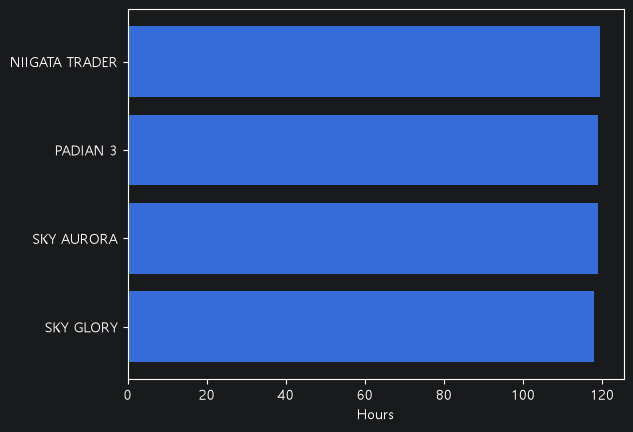

In [16]:
# 오래 머문 순서로 정렬해서 5개 고르기
top5 = df.sort_values("체류시간_h", ascending=False).head(5)
top5.head(5)

# 그래프 그리기
plt.barh(top5["선박명"], top5["체류시간_h"])

plt.xlabel("Hours")  # 머문 시간
plt.gca().invert_yaxis()  # 가장 긴 배를 맨 위로
plt.show()

In [17]:
# 총작업량을 숫자로 변환 _  "3,475." 같은 문자열도 숫자로 바꿉니다.
df["터미널_총작업량"] = pd.to_numeric(
    df["터미널_총작업량"]
      .astype("string")
      .str.replace(",", "", regex=False)
      .str.strip(),
    errors="coerce"
)

In [18]:
print("완전히 같은 중복행:", df.duplicated().sum())
print("체류시간 0 이하:", (df["체류시간_h"] <= 0).sum())

print("작업량 0:", (df["터미널_총작업량"] == 0).sum())
print("작업량 양수:", (df["터미널_총작업량"] > 0).sum())
print("작업량 음수:", (df["터미널_총작업량"] < 0).sum())
print("작업량 결측:", df["터미널_총작업량"].isna().sum())

# 출항이 접안보다 빠른 기록 등 확인
display(
    df.loc[
        df["체류시간_h"] <= 0,
        ["선박명", "터미널", "터미널_접안일시",
         "터미널_출항일시", "체류시간_h"]
    ]
)

완전히 같은 중복행: 119
체류시간 0 이하: 3
작업량 0: 1191
작업량 양수: 34379
작업량 음수: 0
작업량 결측: 0


,선박명,터미널,터미널_접안일시,터미널_출항일시,체류시간_h
12444,STAR CLIPPER,BPT_S,2021-07-04 18:50:00,2021-07-03 23:00:00,-19.833333
15334,TRUST JR,BPT_S,2022-09-16 20:30:00,2022-08-13 17:00:00,-819.500000
18378,KOBE TRADER,BPT_S,2023-08-17 09:10:00,2023-08-16 12:00:00,-21.166667


In [19]:
pd.options.display.float_format = "{:,.2f}".format

In [20]:
# 음수 오류를 제외한 '확인용 자료'입니다.
체류확인 = df.loc[df["체류시간_h"] > 0].copy()

# 체류시간 분포
display(
    체류확인["체류시간_h"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95])
    .to_frame()
)

# 양수 중 가장 짧은 체류 10건
display(
    체류확인.nsmallest(10, "체류시간_h")[
        ["선박명", "터미널", "터미널_접안일시",
         "터미널_출항일시", "터미널_총작업량", "체류시간_h"]
    ]
)

,체류시간_h
count,"35,567.00"
mean,20.53
std,10.82
min,1.00
25%,13.33
50%,18.33
75%,25.00
90%,33.80
95%,39.97
max,119.50


,선박명,터미널,터미널_접안일시,터미널_출항일시,터미널_총작업량,체류시간_h
12519,NSL,BPT_S,2021-07-13 17:00:00,2021-07-13 18:00:00,0.00,1.00
16155,SUNNY DAHLIA,BPT_S,2022-12-03 04:00:00,2022-12-03 05:00:00,29.00,1.00
140,CMA CGM ALHAMBRA,BNCT,2021-07-24 00:40:00,2021-07-24 01:50:00,0.00,1.17
25814,SINOKOR VLADIVOSTOK,PNC,2021-02-11 16:10:00,2021-02-11 17:30:00,36.00,1.33
23903,FESCO YANINA,HPNT,2022-12-09 23:30:00,2022-12-10 01:00:00,9.00,1.50
359,EVER FULL,BNCT,2021-06-28 14:10:00,2021-06-28 15:45:00,0.00,1.58
16356,YOKOHAMA TRADER,BPT_S,2022-12-28 19:20:00,2022-12-28 21:00:00,30.00,1.67
32713,HEUNG-A ULSAN,PNIT,2021-05-26 16:20:00,2021-05-26 18:00:00,6.00,1.67
479,CMA CGM CHENNAI,BNCT,2021-05-17 01:32:00,2021-05-17 03:13:00,0.00,1.68
86,GERDA MAERSK,BNCT,2021-07-02 01:00:00,2021-07-02 03:00:00,0.00,2.00


In [21]:
# 정리 전 자료 보관
df_정리전 = df.copy()

# 완전 중복은 첫 행만 남기기
df = df.drop_duplicates().copy()

# 시간 오류는 따로 보관하고 분석에서 제외
시간오류 = df.loc[df["체류시간_h"] <= 0].copy()
df = df.loc[df["체류시간_h"] > 0].copy()

print("정리 후 행 수:", len(df))
print("남은 완전 중복:", df.duplicated().sum())
print("남은 음수·0시간:", (df["체류시간_h"] <= 0).sum())

정리 후 행 수: 35448
남은 완전 중복: 0
남은 음수·0시간: 0


In [22]:
print("총작업량 0:", (df["터미널_총작업량"] == 0).sum(), "건")

총작업량 0: 1190 건


In [23]:
# 작업량을 숫자로 변환 (쉼표·공백 처리)
작업량 = pd.to_numeric(
    df["터미널_총작업량"]
      .astype("string")
      .str.replace(",", "", regex=False)
      .str.strip(),
    errors="coerce"
)

작업량0 = df.loc[작업량.eq(0)].copy()

print(f"전체 기록: {len(df):,}건")
print(f"작업량 0: {len(작업량0):,}건")
if len(df):
    print(f"비율: {len(작업량0) / len(df):.2%}")
print(f"작업량 결측·숫자 변환 불가: {작업량.isna().sum():,}건")

# 터미널별 작업량 0인 건수
display(
    작업량0.groupby("터미널", dropna=False)
    .size()
    .reset_index(name="작업량0_건수")
    .sort_values("작업량0_건수", ascending=False)
)

# 작업량 0인 상세 기록
확인열 = [
    "선박명", "터미널", "터미널_선사",
    "터미널_접안일시", "터미널_출항일시",
    "터미널_순수물동량", "터미널_Shift수량",
    "터미널_총작업량", "체류시간_h"
]

display(
    작업량0[[열 for 열 in 확인열 if 열 in 작업량0.columns]]
    .sort_values(["터미널", "터미널_접안일시"])
    .reset_index(drop=True)
)

전체 기록: 35,448건
작업량 0: 1,190건
비율: 3.36%
작업량 결측·숫자 변환 불가: 0건


,터미널,작업량0_건수
1,BPTC_G,1051
2,BPT_S,72
4,PNC,42
0,BNCT,13
3,HPNT,12


,선박명,터미널,터미널_선사,터미널_접안일시,터미널_출항일시,터미널_순수물동량,터미널_Shift수량,터미널_총작업량,체류시간_h
0,EVER SHINE,BNCT,EGH,2021-01-16 13:25:00,2021-01-16 22:05:00,0.,0.,0.00,8.67
1,COSCO ITALY,BNCT,EMS,2021-01-31 18:30:00,2021-01-31 20:40:00,0.,0.,0.00,2.17
2,XIN FEI ZHOU,BNCT,COS,2021-02-04 02:10:00,2021-02-04 05:00:00,0.,0.,0.00,2.83
3,OOCL UTAH,BNCT,OOL,2021-02-04 09:05:00,2021-02-04 11:50:00,0.,0.,0.00,2.75
4,APL ESPLANADE,BNCT,CMA,2021-02-15 17:40:00,2021-02-15 22:58:00,0.,0.,0.00,5.30
...,...,...,...,...,...,...,...,...,...
1185,SEBANG20001XX,PNC,PNC,2024-06-10 09:00:00,2024-06-11 08:00:00,0.,0.,0.00,23.00
1186,SEBANG20001XX,PNC,PNC,2024-06-11 09:00:00,2024-06-13 03:00:00,0.,0.,0.00,42.00
1187,SEBANG20001XX,PNC,PNC,2024-08-05 08:00:00,2024-08-06 17:00:00,0.,0.,0.00,33.00
1188,QC41 자재 이동 바지,PNC,PNC,2024-08-06 12:00:00,2024-08-06 17:00:00,0.,0.,0.00,5.00


In [24]:
with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None
):
    display(
        작업량0.loc[
            작업량0["터미널"].eq("BPTC_G"),
            [열 for 열 in 확인열 if 열 in 작업량0.columns]
        ]
        .sort_values("터미널_접안일시", ascending=False)
        .reset_index(drop=True)
    )

,선박명,터미널,터미널_선사,터미널_접안일시,터미널_출항일시,터미널_순수물동량,터미널_Shift수량,터미널_총작업량,체류시간_h
0,토다하나,BPTC_G,BPA,2024-12-26 19:00:00,2024-12-29 19:00:00,0.,0.,0.00,72.00
1,SUNRISE SPRING,BPTC_G,BPA,2024-12-22 19:00:00,2024-12-23 01:00:00,0.,0.,0.00,6.00
2,SKY AURORA,BPTC_G,CKL,2024-12-21 20:00:00,2024-12-22 20:00:00,0.,0.,0.00,24.00
3,POL,BPTC_G,BPA,2024-12-20 21:00:00,2024-12-21 14:00:00,0.,0.,0.00,17.00
4,SEREN,BPTC_G,BPA,2024-12-18 12:00:00,2024-12-20 12:00:00,0.,0.,0.00,48.00
5,SKY GLORY,BPTC_G,CKL,2024-12-15 18:00:00,2024-12-18 11:00:00,0.,0.,0.00,65.00
6,SKY AURORA,BPTC_G,CKL,2024-12-15 08:00:00,2024-12-15 17:00:00,0.,0.,0.00,9.00
7,SKY LILY,BPTC_G,BPA,2024-12-12 21:00:00,2024-12-14 23:00:00,0.,0.,0.00,50.00
8,UML VERONICA,BPTC_G,BPA,2024-12-10 18:00:00,2024-12-14 23:00:00,0.,0.,0.00,101.00
9,SKY AURORA,BPTC_G,CKL,2024-12-09 01:00:00,2024-12-09 18:00:00,0.,0.,0.00,17.00


In [25]:
경로 = PROJECT_ROOT / "0.Data_Gathering" / "Busanport" / "시설사용허가_2101-2412_통합.csv"
허가자료 = read_local_csv(경로, dtype="string")

print("허가자료 크기:", 허가자료.shape)

print("\n기존 데이터 열")
print(df.columns.tolist())

print("\n허가자료 열")
print(허가자료.columns.tolist())

display(허가자료.head())

허가자료 크기: (427544, 32)

기존 데이터 열
['선박명', '터미널_선사', '터미널', '터미널_Shift수량', '터미널_접안일시', '터미널_출항일시', '터미널_순수물동량', '터미널_총작업량', '접안시_최대순간풍속_mps', '접안시_유의파고_m', '접안시_최대파고_m', '접안시_풍속_mps', '접안시_시정_10m', '접안기간_순간풍속최대_mps', '접안기간_유의파고최대_m', '접안기간_풍속평균_mps', '접안기간_시정최저_10m', '체류시간_최대순간풍속_최댓값_mps', '체류시간_최대순간풍속_중앙값_mps', '체류시간_풍속_중앙값_mps', '체류시간_유의파고_중앙값_m', '체류시간_순간최대파고_최댓값_m', '체류시간_순간최대파고_중앙값_m', '체류시간_시정_최솟값_10m', '체류시간_시정_중앙값_10m', '체류시간_특보노출시간(h)', '체류시간_h']

허가자료 열
['순번', '호출부호', '선박명', '입항횟수_연도', '입항횟수_횟수', '입항횟수', '신고톤수', '선박흘수', '선박종류', '부선호출부호', '부선명', '부선호출부호2', '부선명2', '선사/대리점_코드', '선사/대리점_명칭', '요청시설_코드', '요청시설_번호', '요청시설_명칭', '요청기간_FROM', '요청기간_TO', '지정시설_코드', '지정시설_번호', '지정시설_명칭', '지정기간_FROM', '지정기간_TO', '사용목적명', '신청일시', '허가유무', '입항도선여부', '입항적재화물명', '신청구분명', '원본파일명']


,순번,호출부호,선박명,입항횟수_연도,입항횟수_횟수,입항횟수,신고톤수,선박흘수,선박종류,부선호출부호,...,지정시설_명칭,지정기간_FROM,지정기간_TO,사용목적명,신청일시,허가유무,입항도선여부,입항적재화물명,신청구분명,원본파일명
0,1,D5WA6,EASTERN POSEIDON,2021,001,001,3.491,6.3,케미칼 운반선,<NA>,...,남외항 N-3박지,2021-02-02 13:00,2021-02-02 23:00,급유,2021-01-31 22:46,허가완료,N,<NA>,<NA>,시설사용허가-2101.xlsx
1,2,130047,명진호,2021,003,002,460,4.1,급유선,<NA>,...,남외항 N-4박지,2021-01-31 16:10,2021-01-31 18:20,양하,2021-01-31 21:11,허가완료,N,"연료, 에너지",<NA>,시설사용허가-2101.xlsx
2,3,130047,명진호,2021,003,001,460,4.1,급유선,<NA>,...,5물량장 1선석,2021-01-30 7:45,2021-01-31 15:10,기타,2021-01-31 21:10,허가완료,N,"연료, 에너지",<NA>,시설사용허가-2101.xlsx
3,4,DSNY2,삼표301호,2021,006,001,4.424,4.5,기타 예선,042053,...,선기조합-11(송린),2021-02-02 17:40,2021-02-03 8:10,양하,2021-01-31 20:53,허가완료,N,"토석,소금",<NA>,시설사용허가-2101.xlsx
4,5,D5DN9,QINGDAO TOWER,2021,001,001,39.941,12,풀컨테이너선,<NA>,...,자성대부두 61선석,2021-02-01 20:00,2021-02-02 14:00,양적하,2021-01-31 19:51,허가완료,Y,기타,<NA>,시설사용허가-2101.xlsx


In [26]:
import pandas as pd

# 작업량 0인 기록
대상 = 작업량0.copy()

# BPTC_G만 보려면 아래 줄의 #을 지우세요.
대상 = 대상.loc[대상["터미널"].eq("BPTC_G")].copy()

대상 = 대상.reset_index(drop=True)
대상["대조번호"] = 대상.index + 1

# 띄어쓰기·대소문자 차이를 정리해 선박명 비교
def 선박명정리(s):
    return (
        s.astype("string")
        .str.upper()
        .str.replace(r"\s+", "", regex=True)
        .str.strip()
        .replace("", pd.NA)
    )

대상["선박키"] = 선박명정리(대상["선박명"])
허가 = 허가자료.copy()
허가["선박키"] = 선박명정리(허가["선박명"])

# 날짜 변환
대상["접안"] = pd.to_datetime(
    대상["터미널_접안일시"], errors="coerce"
)
대상["출항"] = pd.to_datetime(
    대상["터미널_출항일시"], errors="coerce"
)

허가["허가시작"] = pd.to_datetime(
    허가["지정기간_FROM"], errors="coerce"
)
허가["허가종료"] = pd.to_datetime(
    허가["지정기간_TO"], errors="coerce"
)

# 허가 쪽 열 이름을 구분
허가열 = [
    "선박키", "호출부호",
    "지정시설_코드", "지정시설_번호", "지정시설_명칭",
    "허가시작", "허가종료",
    "사용목적명", "허가유무", "원본파일명"
]
허가 = 허가[허가열].rename(
    columns={c: f"허가_{c}" for c in 허가열 if c != "선박키"}
)

# 선박명이 같은 허가 기록 연결 (빈 선박명 제외)
후보 = 대상.loc[대상["선박키"].notna()].merge(
    허가.loc[허가["선박키"].notna()],
    on="선박키",
    how="inner"
)

# 두 기간이 실제로 겹치는 기록만 추출
정상기간 = (
    후보["출항"].gt(후보["접안"])
    & 후보["허가_허가종료"].gt(후보["허가_허가시작"])
)

기간겹침 = (
    후보["접안"].lt(후보["허가_허가종료"])
    & 후보["출항"].gt(후보["허가_허가시작"])
)

대조결과 = 후보.loc[정상기간 & 기간겹침].copy()

# 겹치는 시간 계산
대조결과["겹침시간_h"] = (
    대조결과[["출항", "허가_허가종료"]].min(axis=1)
    - 대조결과[["접안", "허가_허가시작"]].max(axis=1)
).dt.total_seconds().div(3600).round(2)

# 후보가 없는 기존 기록도 따로 보관
후보없음 = 대상.loc[
    ~대상["대조번호"].isin(대조결과["대조번호"])
].copy()

print(f"작업량 0인 대상: {len(대상):,}건")
print(f"허가 후보가 있는 대상: {대조결과['대조번호'].nunique():,}건")
print(f"허가 후보가 없는 대상: {len(후보없음):,}건")
print(f"연결된 허가 후보: {len(대조결과):,}행")

표시열 = [
    "대조번호", "선박명", "터미널",
    "터미널_접안일시", "터미널_출항일시",
    "터미널_총작업량", "체류시간_h",
    "허가_호출부호", "허가_지정시설_코드",
    "허가_지정시설_번호", "허가_지정시설_명칭",
    "허가_허가시작", "허가_허가종료",
    "허가_사용목적명", "허가_허가유무",
    "겹침시간_h", "허가_원본파일명"
]

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None
):
    display(
        대조결과[표시열]
        .sort_values(
            ["터미널_접안일시", "대조번호", "겹침시간_h"],
            ascending=[False, True, False]
        )
        .reset_index(drop=True)
    )

작업량 0인 대상: 1,051건
허가 후보가 있는 대상: 794건
허가 후보가 없는 대상: 257건
연결된 허가 후보: 1,031행


,대조번호,선박명,터미널,터미널_접안일시,터미널_출항일시,터미널_총작업량,체류시간_h,허가_호출부호,허가_지정시설_코드,허가_지정시설_번호,허가_지정시설_명칭,허가_허가시작,허가_허가종료,허가_사용목적명,허가_허가유무,겹침시간_h,허가_원본파일명
0,1050,SUNRISE SPRING,BPTC_G,2024-12-22 19:00:00,2024-12-23 01:00:00,0.00,6.00,3EHA4,MBR,02,감만부두 2선석(신선대감만터미널),2024-12-22 19:00:00,2024-12-23 08:00:00,급유,허가완료,6.00,시설사용허가-2412.xlsx
1,1049,SKY AURORA,BPTC_G,2024-12-21 20:00:00,2024-12-22 20:00:00,0.00,24.00,DSQN2,MBR,02,감만부두 2선석(신선대감만터미널),2024-12-21 20:00:00,2024-12-22 20:00:00,양적하,허가완료,24.00,시설사용허가-2412.xlsx
2,1046,SKY GLORY,BPTC_G,2024-12-15 18:00:00,2024-12-18 11:00:00,0.00,65.00,DSQP3,MBR,02,감만부두 2선석(신선대감만터미널),2024-12-15 16:00:00,2024-12-18 13:00:00,양하,허가완료,65.00,시설사용허가-2412.xlsx
3,1045,SKY AURORA,BPTC_G,2024-12-15 08:00:00,2024-12-15 17:00:00,0.00,9.00,DSQN2,MBR,02,감만부두 2선석(신선대감만터미널),2024-12-15 06:00:00,2024-12-15 15:00:00,적하,허가완료,7.00,시설사용허가-2412.xlsx
4,1041,SKY AURORA,BPTC_G,2024-12-09 01:00:00,2024-12-09 18:00:00,0.00,17.00,DSQN2,MBR,02,감만부두 2선석(신선대감만터미널),2024-12-09 03:00:00,2024-12-10 15:00:00,양적하,허가완료,15.00,시설사용허가-2412.xlsx
5,1042,KEOYOUNG SUN 5,BPTC_G,2024-12-08 17:00:00,2024-12-10 15:00:00,0.00,46.00,D7US,MBR,02,감만부두 2선석(신선대감만터미널),2024-12-08 16:00:00,2024-12-09 22:00:00,수리,허가완료,29.00,시설사용허가-2412.xlsx
6,1040,SKY AURORA,BPTC_G,2024-11-30 16:00:00,2024-12-01 16:00:00,0.00,24.00,DSQN2,MBR,02,감만부두 2선석(신선대감만터미널),2024-11-30 16:00:00,2024-12-01 16:00:00,양적하,허가완료,24.00,시설사용허가-2411.xlsx
7,1039,SKY GLORY,BPTC_G,2024-11-25 17:00:00,2024-11-27 20:00:00,0.00,51.00,DSQP3,MBR,02,감만부두 2선석(신선대감만터미널),2024-11-25 17:00:00,2024-11-27 20:00:00,양적하,허가완료,51.00,시설사용허가-2411.xlsx
8,1037,NARVA,BPTC_G,2024-11-25 05:00:00,2024-11-26 23:00:00,0.00,42.00,UDOP,WAN,02,남외항 N-2박지,2024-11-26 09:00:00,2024-11-26 18:00:00,급유,허가완료,9.00,시설사용허가-2411.xlsx
9,1032,SKY GLORY,BPTC_G,2024-11-17 15:00:00,2024-11-19 17:00:00,0.00,50.00,DSQP3,MBR,02,감만부두 2선석(신선대감만터미널),2024-11-17 17:00:00,2024-11-19 20:00:00,접안대기,허가완료,48.00,시설사용허가-2411.xlsx


In [27]:
양적하결과 = 대조결과.loc[
    대조결과["허가_사용목적명"]
    .astype("string")
    .str.strip()
    .isin(["양하", "적하", "양적하"])
].copy()

print(f"추출 결과: {len(양적하결과):,}행")
print(f"작업량 0인 대상 기록: {양적하결과['대조번호'].nunique():,}건")

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None
):
    display(
        양적하결과[표시열]
        .sort_values("터미널_접안일시", ascending=False)
        .reset_index(drop=True)
    )

추출 결과: 515행
작업량 0인 대상 기록: 468건


,대조번호,선박명,터미널,터미널_접안일시,터미널_출항일시,터미널_총작업량,체류시간_h,허가_호출부호,허가_지정시설_코드,허가_지정시설_번호,허가_지정시설_명칭,허가_허가시작,허가_허가종료,허가_사용목적명,허가_허가유무,겹침시간_h,허가_원본파일명
0,1049,SKY AURORA,BPTC_G,2024-12-21 20:00:00,2024-12-22 20:00:00,0.00,24.00,DSQN2,MBR,02,감만부두 2선석(신선대감만터미널),2024-12-21 20:00:00,2024-12-22 20:00:00,양적하,허가완료,24.00,시설사용허가-2412.xlsx
1,1046,SKY GLORY,BPTC_G,2024-12-15 18:00:00,2024-12-18 11:00:00,0.00,65.00,DSQP3,MBR,02,감만부두 2선석(신선대감만터미널),2024-12-15 16:00:00,2024-12-18 13:00:00,양하,허가완료,65.00,시설사용허가-2412.xlsx
2,1045,SKY AURORA,BPTC_G,2024-12-15 08:00:00,2024-12-15 17:00:00,0.00,9.00,DSQN2,MBR,02,감만부두 2선석(신선대감만터미널),2024-12-15 06:00:00,2024-12-15 15:00:00,적하,허가완료,7.00,시설사용허가-2412.xlsx
3,1041,SKY AURORA,BPTC_G,2024-12-09 01:00:00,2024-12-09 18:00:00,0.00,17.00,DSQN2,MBR,02,감만부두 2선석(신선대감만터미널),2024-12-09 03:00:00,2024-12-10 15:00:00,양적하,허가완료,15.00,시설사용허가-2412.xlsx
4,1040,SKY AURORA,BPTC_G,2024-11-30 16:00:00,2024-12-01 16:00:00,0.00,24.00,DSQN2,MBR,02,감만부두 2선석(신선대감만터미널),2024-11-30 16:00:00,2024-12-01 16:00:00,양적하,허가완료,24.00,시설사용허가-2411.xlsx
5,1039,SKY GLORY,BPTC_G,2024-11-25 17:00:00,2024-11-27 20:00:00,0.00,51.00,DSQP3,MBR,02,감만부두 2선석(신선대감만터미널),2024-11-25 17:00:00,2024-11-27 20:00:00,양적하,허가완료,51.00,시설사용허가-2411.xlsx
6,1031,SKY AURORA,BPTC_G,2024-11-14 03:00:00,2024-11-17 15:00:00,0.00,84.00,DSQN2,MBR,02,감만부두 2선석(신선대감만터미널),2024-11-13 20:00:00,2024-11-17 15:00:00,양적하,허가완료,84.00,시설사용허가-2411.xlsx
7,1027,SKY AURORA,BPTC_G,2024-11-04 21:00:00,2024-11-05 17:00:00,0.00,20.00,DSQN2,MBR,02,감만부두 2선석(신선대감만터미널),2024-11-04 18:00:00,2024-11-05 20:00:00,양적하,허가완료,20.00,시설사용허가-2411.xlsx
8,1024,SKY AURORA,BPTC_G,2024-10-30 01:00:00,2024-10-30 20:00:00,0.00,19.00,DSQN2,MBR,02,감만부두 2선석(신선대감만터미널),2024-10-30 00:00:00,2024-10-30 20:00:00,양적하,허가완료,19.00,시설사용허가-2410.xlsx
9,1018,SKY GLORY,BPTC_G,2024-10-14 01:00:00,2024-10-14 15:00:00,0.00,14.00,DSQP3,MBR,02,감만부두 2선석(신선대감만터미널),2024-10-14 00:00:00,2024-10-14 17:00:00,양적하,허가완료,14.00,시설사용허가-2410.xlsx


In [28]:
import unicodedata
톤수파일후보 = [p for p in (PROJECT_ROOT / "0.Data_Gathering" / "Busanport").glob("*.csv")
      if "선박 입출항 집계 정보" in unicodedata.normalize("NFC", p.stem)]
if len(톤수파일후보) != 1:
    raise FileNotFoundError(f"선박 입출항 집계 CSV를 하나로 식별할 수 없습니다: {톤수파일후보}")
톤수자료 = read_local_csv(톤수파일후보[0], dtype="string")
print("열 이름:", 톤수자료.columns.tolist())
display(톤수자료.head())


열 이름: ['청코드', '선박키', '입항연도', '입항회수', '업체코드', '업체명', '차항지코드1', '차항지코드2', '차항지명', '적재톤수', '환적톤수', '위험물톤수', '징수결정톤수', '총톤수', '국제총톤수', '선박국적코드', '선박국적명', '선박종류', '선박종류명', '선박명', '출항예정일', '전출항지출항일시', '전출항지코드1', '전출항지코드2', '전출항지명', '입항일시', '출항일시', '양하톤수', '선원수', '전체승객수']


,청코드,선박키,입항연도,입항회수,업체코드,업체명,차항지코드1,차항지코드2,차항지명,적재톤수,...,출항예정일,전출항지출항일시,전출항지코드1,전출항지코드2,전출항지명,입항일시,출항일시,양하톤수,선원수,전체승객수
0,020,013045,2025,001,B*******,이*******,<NA>,<NA>,<NA>,0,...,<NA>,<NA>,<NA>,<NA>,<NA>,2025-01-01 00:00:00,2025-01-01 00:00:00,0,0,0
1,020,716141,2025,001,B*******,용*******,<NA>,<NA>,<NA>,0,...,<NA>,<NA>,<NA>,<NA>,<NA>,2025-01-01 00:00:00,2025-01-01 00:00:00,0,0,0
2,020,060457,2025,001,B*******,팔*******,<NA>,<NA>,<NA>,0,...,<NA>,<NA>,<NA>,<NA>,<NA>,2025-01-01 00:00:00,2025-01-01 00:00:00,0,0,0
3,020,2016-40,2025,001,B*******,주*******,<NA>,<NA>,<NA>,0,...,<NA>,<NA>,<NA>,<NA>,<NA>,2025-01-01 00:00:00,2025-01-01 00:00:00,0,0,0
4,020,901151,2025,001,B*******,주*******,<NA>,<NA>,<NA>,0,...,<NA>,<NA>,<NA>,<NA>,<NA>,2025-01-01 00:00:00,2025-01-01 00:00:00,0,0,0


In [29]:
print("① 원래 체류시간 데이터 열")
print(df.columns.tolist())

print("\n② 총톤수 자료 열")
print(톤수자료.columns.tolist())

print("\n③ 총톤수 자료 미리보기")
display(톤수자료.head())

① 원래 체류시간 데이터 열
['선박명', '터미널_선사', '터미널', '터미널_Shift수량', '터미널_접안일시', '터미널_출항일시', '터미널_순수물동량', '터미널_총작업량', '접안시_최대순간풍속_mps', '접안시_유의파고_m', '접안시_최대파고_m', '접안시_풍속_mps', '접안시_시정_10m', '접안기간_순간풍속최대_mps', '접안기간_유의파고최대_m', '접안기간_풍속평균_mps', '접안기간_시정최저_10m', '체류시간_최대순간풍속_최댓값_mps', '체류시간_최대순간풍속_중앙값_mps', '체류시간_풍속_중앙값_mps', '체류시간_유의파고_중앙값_m', '체류시간_순간최대파고_최댓값_m', '체류시간_순간최대파고_중앙값_m', '체류시간_시정_최솟값_10m', '체류시간_시정_중앙값_10m', '체류시간_특보노출시간(h)', '체류시간_h']

② 총톤수 자료 열
['청코드', '선박키', '입항연도', '입항회수', '업체코드', '업체명', '차항지코드1', '차항지코드2', '차항지명', '적재톤수', '환적톤수', '위험물톤수', '징수결정톤수', '총톤수', '국제총톤수', '선박국적코드', '선박국적명', '선박종류', '선박종류명', '선박명', '출항예정일', '전출항지출항일시', '전출항지코드1', '전출항지코드2', '전출항지명', '입항일시', '출항일시', '양하톤수', '선원수', '전체승객수']

③ 총톤수 자료 미리보기


,청코드,선박키,입항연도,입항회수,업체코드,업체명,차항지코드1,차항지코드2,차항지명,적재톤수,...,출항예정일,전출항지출항일시,전출항지코드1,전출항지코드2,전출항지명,입항일시,출항일시,양하톤수,선원수,전체승객수
0,020,013045,2025,001,B*******,이*******,<NA>,<NA>,<NA>,0,...,<NA>,<NA>,<NA>,<NA>,<NA>,2025-01-01 00:00:00,2025-01-01 00:00:00,0,0,0
1,020,716141,2025,001,B*******,용*******,<NA>,<NA>,<NA>,0,...,<NA>,<NA>,<NA>,<NA>,<NA>,2025-01-01 00:00:00,2025-01-01 00:00:00,0,0,0
2,020,060457,2025,001,B*******,팔*******,<NA>,<NA>,<NA>,0,...,<NA>,<NA>,<NA>,<NA>,<NA>,2025-01-01 00:00:00,2025-01-01 00:00:00,0,0,0
3,020,2016-40,2025,001,B*******,주*******,<NA>,<NA>,<NA>,0,...,<NA>,<NA>,<NA>,<NA>,<NA>,2025-01-01 00:00:00,2025-01-01 00:00:00,0,0,0
4,020,901151,2025,001,B*******,주*******,<NA>,<NA>,<NA>,0,...,<NA>,<NA>,<NA>,<NA>,<NA>,2025-01-01 00:00:00,2025-01-01 00:00:00,0,0,0


In [30]:
import pandas as pd

def 선박키만들기(s):
    return (
        s.astype("string")
        .str.upper()
        .str.replace(r"\s+", "", regex=True)
        .replace("", pd.NA)
    )

# 총톤수 자료 정리
톤수기준 = 톤수자료[["선박명", "총톤수"]].copy()
톤수기준["_선박키"] = 선박키만들기(톤수기준["선박명"])
톤수기준["총톤수"] = pd.to_numeric(
    톤수기준["총톤수"]
    .astype("string")
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

# 선박명과 양수인 총톤수가 있는 자료만 사용
유효 = 톤수기준.loc[
    톤수기준["_선박키"].notna()
    & 톤수기준["총톤수"].gt(0)
].copy()

# 같은 선박명에 서로 다른 총톤수가 있는지 확인
톤수종류수 = 유효.groupby("_선박키")["총톤수"].nunique()
충돌키 = 톤수종류수[톤수종류수 > 1].index

총톤수_확인필요 = (
    유효.loc[유효["_선박키"].isin(충돌키), ["선박명", "총톤수"]]
    .drop_duplicates()
    .sort_values(["선박명", "총톤수"])
)

# 총톤수가 한 값으로 확인되는 선박만 매칭
톤수맵 = (
    유효.loc[~유효["_선박키"].isin(충돌키)]
    .drop_duplicates("_선박키")
    .set_index("_선박키")["총톤수"]
)

def 총톤수붙이기(자료):
    결과 = 자료.copy()
    키 = 선박키만들기(결과["선박명"])

    결과["총톤수"] = 키.map(톤수맵).astype("Float64")
    결과["총톤수_매칭상태"] = "매칭 자료 없음"
    결과.loc[결과["총톤수"].notna(), "총톤수_매칭상태"] = "매칭"
    결과.loc[키.isin(충돌키), "총톤수_매칭상태"] = "서로 다른 총톤수 확인 필요"

    return 결과

# 원래 데이터 전체와 기존 결과 모두에 추가
df = 총톤수붙이기(df)
작업량0 = 총톤수붙이기(작업량0)
대조결과 = 총톤수붙이기(대조결과)
양적하결과 = 총톤수붙이기(양적하결과)

# 기존 표시 목록에도 추가
확인열 = list(dict.fromkeys(확인열 + ["총톤수", "총톤수_매칭상태"]))
표시열 = list(dict.fromkeys(표시열 + ["총톤수", "총톤수_매칭상태"]))

print("원래 체류시간 데이터 전체 매칭 결과")
display(df["총톤수_매칭상태"].value_counts(dropna=False))

display(
    df[[
        "선박명", "터미널", "터미널_접안일시",
        "총톤수", "총톤수_매칭상태"
    ]].head(20)
)

print("같은 선박명에 서로 다른 총톤수가 있는 자료")
display(총톤수_확인필요)

원래 체류시간 데이터 전체 매칭 결과


총톤수_매칭상태
매칭 자료 없음           33587
매칭                  1818
서로 다른 총톤수 확인 필요       43
Name: count, dtype: int64

,선박명,터미널,터미널_접안일시,총톤수,총톤수_매칭상태
4,NORTHERN GENERAL,BNCT,2021-01-01 03:20:00,<NA>,매칭 자료 없음
5,PRESIDENT FD ROOSEVELT,BNCT,2021-01-01 15:20:00,<NA>,매칭 자료 없음
6,PRESIDENT CLEVELAND,BNCT,2021-01-02 10:20:00,<NA>,매칭 자료 없음
7,COSCO GUANGZHOU,BNCT,2021-01-01 21:25:00,<NA>,매칭 자료 없음
8,CONTSHIP DAY,BNCT,2021-01-03 09:15:00,<NA>,매칭 자료 없음
9,XIN TIAN JIN,BNCT,2021-01-03 01:55:00,"66,433.00",매칭
10,QI YUN HE,BNCT,2021-01-03 07:15:00,"16,738.00",매칭
11,CMA CGM RABELAIS,BNCT,2021-01-03 02:12:00,<NA>,매칭 자료 없음
12,APL GUAM,BNCT,2021-01-03 20:15:00,<NA>,매칭 자료 없음
13,OOCL UTAH,BNCT,2021-01-04 07:10:00,<NA>,매칭 자료 없음


같은 선박명에 서로 다른 총톤수가 있는 자료


,선박명,총톤수
846,105청룡호,44
41746,105청룡호,45
4778,5 현성,1716
4424,5 현성,3419
18873,FENG SHUN,1976
24346,FENG SHUN,2997
43196,HONG YANG,1972
36802,HONG YANG,39727
1435,MSC LUDOVICA,75590
21660,MSC LUDOVICA,76490


In [31]:
확인필요 = df.loc[
    df["총톤수_매칭상태"].eq("서로 다른 총톤수 확인 필요")
]

print(f"체류시간 기록: {len(확인필요):,}건")
print(f"선박 수: {선박키만들기(확인필요['선박명']).nunique():,}척")

체류시간 기록: 43건
선박 수: 2척


In [32]:
# 1. 총톤수 자료의 입출항 기간 준비
기간기준 = 톤수자료[[
    "선박명", "총톤수", "입항일시", "출항일시"
]].copy()

기간기준["_선박키"] = 선박키만들기(기간기준["선박명"])

기간기준["총톤수"] = pd.to_numeric(
    기간기준["총톤수"].astype("string")
    .str.replace(",", "", regex=False).str.strip(),
    errors="coerce"
)

기간기준["_입항"] = pd.to_datetime(
    기간기준["입항일시"], errors="coerce"
)
기간기준["_출항"] = pd.to_datetime(
    기간기준["출항일시"], errors="coerce"
)

기간기준 = 기간기준.loc[
    기간기준["_선박키"].notna()
    & 기간기준["총톤수"].gt(0)
    & 기간기준["_출항"].gt(기간기준["_입항"])
].drop_duplicates(["_선박키", "총톤수", "_입항", "_출항"])


# 2. 충돌한 기록만 기간을 이용해 다시 매칭
def 기간으로보완(자료):
    결과 = 자료.copy()
    대상마스크 = 결과["총톤수_매칭상태"].eq(
        "서로 다른 총톤수 확인 필요"
    )

    대상 = 결과.loc[
        대상마스크,
        ["선박명", "터미널_접안일시", "터미널_출항일시"]
    ].copy()

    # 원래 행 순서와 개수를 유지하기 위한 번호
    대상["_행번호"] = [
        i for i, 해당 in enumerate(대상마스크) if 해당
    ]
    대상["_선박키"] = 선박키만들기(대상["선박명"])
    대상["_접안"] = pd.to_datetime(
        대상["터미널_접안일시"], errors="coerce"
    )
    대상["_터미널출항"] = pd.to_datetime(
        대상["터미널_출항일시"], errors="coerce"
    )

    후보 = 대상.loc[대상["_선박키"].notna()].merge(
        기간기준[["_선박키", "총톤수", "_입항", "_출항"]],
        on="_선박키",
        how="inner"
    )

    # 유효한 체류 기간끼리 겹치는 경우만 선택
    후보 = 후보.loc[
        후보["_터미널출항"].gt(후보["_접안"])
        & 후보["_접안"].lt(후보["_출항"])
        & 후보["_터미널출항"].gt(후보["_입항"])
    ]

    집계 = 후보.groupby("_행번호")["총톤수"].agg(
        종류수="nunique",
        톤수="first"
    )

    # 기간으로 좁힌 뒤 총톤수가 하나인 경우만 반영
    확정 = 집계.loc[집계["종류수"].eq(1), "톤수"]

    톤수위치 = 결과.columns.get_loc("총톤수")
    상태위치 = 결과.columns.get_loc("총톤수_매칭상태")

    for 행번호, 톤수 in 확정.items():
        결과.iloc[int(행번호), 톤수위치] = 톤수
        결과.iloc[int(행번호), 상태위치] = "선박명+기간 매칭"

    return 결과


# 3. 전체 데이터와 기존 결과에 반영
df = 기간으로보완(df)
작업량0 = 기간으로보완(작업량0)
대조결과 = 기간으로보완(대조결과)
양적하결과 = 기간으로보완(양적하결과)

print("보완 후 전체 매칭 결과")
display(df["총톤수_매칭상태"].value_counts(dropna=False))

보완 후 전체 매칭 결과


총톤수_매칭상태
매칭 자료 없음           33587
매칭                  1818
서로 다른 총톤수 확인 필요       43
Name: count, dtype: int64

In [33]:
# 원본 df는 보존
제외대상 = df["총톤수_매칭상태"].eq("매칭 자료 없음")

print(f"매칭 자료 없어 제외: {제외대상.sum():,}건")

나머지 = df.loc[~제외대상].copy()

# 총톤수가 아직 미확정인 기록은 별도 보관
총톤수_미확정 = 나머지.loc[나머지["총톤수"].isna()].copy()

# 최종 분석용: 총톤수가 매칭된 기록만
최종자료 = (
    나머지.loc[나머지["총톤수"].notna()]
    .reset_index(drop=True)
)

print(f"총톤수 미확정 별도 보관: {len(총톤수_미확정):,}건")
print(f"총톤수 매칭된 최종자료: {len(최종자료):,}건")

display(
    최종자료[[
        "선박명", "터미널",
        "터미널_접안일시", "터미널_출항일시",
        "체류시간_h", "총톤수", "총톤수_매칭상태"
    ]].head(20)
)

매칭 자료 없어 제외: 33,587건
총톤수 미확정 별도 보관: 43건
총톤수 매칭된 최종자료: 1,818건


,선박명,터미널,터미널_접안일시,터미널_출항일시,체류시간_h,총톤수,총톤수_매칭상태
0,XIN TIAN JIN,BNCT,2021-01-03 01:55:00,2021-01-04 04:50:00,26.92,"66,433.00",매칭
1,QI YUN HE,BNCT,2021-01-03 07:15:00,2021-01-04 06:45:00,23.50,"16,738.00",매칭
2,CMA CGM TITAN,BNCT,2021-01-07 22:24:00,2021-01-08 07:00:00,8.60,"131,332.00",매칭
3,LING YUN HE,BNCT,2021-01-11 15:35:00,2021-01-12 15:40:00,24.08,"20,569.00",매칭
4,QI YUN HE,BNCT,2021-01-13 22:55:00,2021-01-14 16:45:00,17.83,"16,738.00",매칭
5,OOCL NEWYORK,BNCT,2021-01-18 04:25:00,2021-01-18 20:10:00,15.75,"195,636.00",매칭
6,QI YUN HE,BNCT,2021-01-23 22:10:00,2021-01-25 10:35:00,36.42,"16,738.00",매칭
7,LING YUN HE,BNCT,2021-01-25 00:50:00,2021-01-25 22:55:00,22.08,"20,569.00",매칭
8,QI YUN HE,BNCT,2021-07-03 20:20:00,2021-07-04 16:45:00,20.42,"16,738.00",매칭
9,LING YUN HE,BNCT,2021-07-13 17:55:00,2021-07-14 14:50:00,20.92,"20,569.00",매칭


In [34]:
BPTC_G자료 = (
    df.loc[df["터미널"].eq("BPTC_G")]
    .sort_values("터미널_접안일시", ascending=False)
    .reset_index(drop=True)
)

print(f"전체: {len(BPTC_G자료):,}건")
print(f"총톤수 있음: {BPTC_G자료['총톤수'].notna().sum():,}건")
print(f"총톤수 없음: {BPTC_G자료['총톤수'].isna().sum():,}건")

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None
):
    display(BPTC_G자료[[
        "선박명", "터미널_접안일시", "터미널_출항일시",
        "총톤수", "총톤수_매칭상태"
    ]])

전체: 7,306건
총톤수 있음: 289건
총톤수 없음: 7,017건


,선박명,터미널_접안일시,터미널_출항일시,총톤수,총톤수_매칭상태
0,HONG YANG 28,2024-12-31 11:30:00,2024-12-31 21:00:00,<NA>,매칭 자료 없음
1,POS GUANGZHOU,2024-12-30 23:00:00,2024-12-31 07:00:00,<NA>,매칭 자료 없음
2,PACIFIC MONACO,2024-12-30 21:40:00,2024-12-31 10:00:00,<NA>,매칭 자료 없음
3,SITC RENHE,2024-12-30 09:00:00,2024-12-30 18:00:00,<NA>,매칭 자료 없음
4,JIFA BOHAI,2024-12-30 02:40:00,2024-12-30 05:00:00,<NA>,매칭 자료 없음
5,POS YOKOHAMA,2024-12-29 23:55:00,2024-12-30 12:00:00,<NA>,매칭 자료 없음
6,ZHONG WAI YUN SHENZHEN,2024-12-29 10:40:00,2024-12-30 01:00:00,<NA>,매칭 자료 없음
7,GRACE MERCHANT,2024-12-29 08:50:00,2024-12-29 22:00:00,<NA>,매칭 자료 없음
8,PACIFIC TIANJIN,2024-12-29 07:00:00,2024-12-29 19:00:00,<NA>,매칭 자료 없음
9,TS GUANGZHOU,2024-12-29 05:00:00,2024-12-29 23:00:00,<NA>,매칭 자료 없음


In [35]:
대상 = df.loc[df["터미널"].eq("BPTC_G")]

print(f"BPTC_G 전체: {len(대상):,}건")
print(f"총톤수 매칭: {대상['총톤수'].notna().sum():,}건")
print(f"총톤수 미매칭: {대상['총톤수'].isna().sum():,}건")

BPTC_G 전체: 7,306건
총톤수 매칭: 289건
총톤수 미매칭: 7,017건


In [36]:
대상 = df.loc[df["터미널"].eq("BPTC_G")].copy()
대상["연도"] = pd.to_datetime(
    대상["터미널_접안일시"], errors="coerce"
).dt.year

for 연도, 자료 in 대상.groupby("연도"):
    미매칭수 = 자료["총톤수"].isna().sum()
    print(
        f"{int(연도)}년: 전체 {len(자료):,}건 / "
        f"미매칭 {미매칭수:,}건 ({미매칭수 / len(자료):.1%})"
    )

2021년: 전체 1,859건 / 미매칭 1,779건 (95.7%)
2022년: 전체 1,674건 / 미매칭 1,641건 (98.0%)
2023년: 전체 1,964건 / 미매칭 1,889건 (96.2%)
2024년: 전체 1,809건 / 미매칭 1,708건 (94.4%)


In [37]:
삼분할자료 = df.loc[
    df["터미널"].eq("BPTC_G") & df["총톤수"].notna()
].copy()

삼분할자료["총톤수"] = pd.to_numeric(
    삼분할자료["총톤수"], errors="raise"
)

삼분할자료["톤수그룹"] = pd.qcut(
    삼분할자료["총톤수"],
    q=3,
    labels=["하위", "중위", "상위"]
)

print(f"전체: {len(삼분할자료):,}건")

for 그룹, 자료 in 삼분할자료.groupby("톤수그룹", observed=True):
    print(
        f"{그룹}: {len(자료):,}건 / "
        f"총톤수 {자료['총톤수'].min():,.0f}"
        f" ~ {자료['총톤수'].max():,.0f}"
    )

전체: 289건
하위: 162건 / 총톤수 378 ~ 9,925
중위: 41건 / 총톤수 9,953 ~ 16,488
상위: 86건 / 총톤수 16,659 ~ 66,433


In [38]:
자료 = 삼분할자료.copy()

자료["터미널_총작업량"] = pd.to_numeric(
    자료["터미널_총작업량"].astype("string")
    .str.replace(",", "", regex=False),
    errors="coerce"
)

자료 = 자료.loc[자료["터미널_총작업량"].gt(0)]

for 그룹, 구간자료 in 자료.groupby("톤수그룹", observed=True):
    print(
        f"{그룹}: {len(구간자료):,}건 / "
        f"평균 총작업량: "
        f"{구간자료['터미널_총작업량'].mean():,.2f}"
    )

하위: 130건 / 평균 총작업량: 443.16
중위: 23건 / 평균 총작업량: 628.04
상위: 68건 / 평균 총작업량: 855.34


In [39]:
대체값 = {
    "하위": 419.98,
    "중위": 530.23,
    "상위": 771.70
}

삼분할자료 = 삼분할자료.copy()

작업량 = pd.to_numeric(
    삼분할자료["터미널_총작업량"].astype("string")
    .str.replace(",", "", regex=False),
    errors="coerce"
)

if "총작업량_원본" not in 삼분할자료.columns:
    삼분할자료["총작업량_원본"] = 삼분할자료["터미널_총작업량"].copy()

삼분할자료["터미널_총작업량"] = 작업량.astype("Float64")

교체대상 = 작업량.eq(0).fillna(False)
삼분할자료["총작업량_평균대체여부"] = 교체대상

구간평균 = (
    삼분할자료["톤수그룹"].astype("string")
    .map(대체값).astype("Float64")
)

삼분할자료.loc[교체대상, "터미널_총작업량"] = 구간평균[교체대상]

for 그룹 in 대체값:
    건수 = (
        교체대상 & 삼분할자료["톤수그룹"].eq(그룹)
    ).sum()
    print(f"{그룹}: {건수:,}건 → {대체값[그룹]:,.2f}로 대체")

print(f"총 {교체대상.sum():,}건 대체 완료")

하위: 32건 → 419.98로 대체
중위: 18건 → 530.23로 대체
상위: 18건 → 771.70로 대체
총 68건 대체 완료


In [40]:
작업량 = pd.to_numeric(
    양적하결과["터미널_총작업량"].astype("string")
    .str.replace(",", "", regex=False),
    errors="coerce"
)

BPTC_G_작업량0_양적하 = 양적하결과.loc[
    양적하결과["터미널"].eq("BPTC_G")
    & 작업량.eq(0)
    & 양적하결과["허가_사용목적명"].astype("string").str.strip()
      .isin(["양하", "적하", "양적하"])
    & 양적하결과["허가_지정시설_코드"].eq("MBR")
    & 양적하결과["허가_지정시설_명칭"].str.contains(
        "신선대감만터미널", na=False
    )
].copy()

print(
    f"체류 기록: "
    f"{BPTC_G_작업량0_양적하['대조번호'].nunique():,}건"
)
print(f"연결된 허가 기록: {len(BPTC_G_작업량0_양적하):,}행")

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None
):
    display(
        BPTC_G_작업량0_양적하[[
            "대조번호", "선박명",
            "터미널_접안일시", "터미널_출항일시",
            "총톤수", "터미널_총작업량",
            "허가_사용목적명", "허가_지정시설_명칭"
        ]]
        .sort_values("터미널_접안일시", ascending=False)
        .reset_index(drop=True)
    )

체류 기록: 157건
연결된 허가 기록: 159행


,대조번호,선박명,터미널_접안일시,터미널_출항일시,총톤수,터미널_총작업량,허가_사용목적명,허가_지정시설_명칭
0,1049,SKY AURORA,2024-12-21 20:00:00,2024-12-22 20:00:00,<NA>,0.00,양적하,감만부두 2선석(신선대감만터미널)
1,1046,SKY GLORY,2024-12-15 18:00:00,2024-12-18 11:00:00,<NA>,0.00,양하,감만부두 2선석(신선대감만터미널)
2,1045,SKY AURORA,2024-12-15 08:00:00,2024-12-15 17:00:00,<NA>,0.00,적하,감만부두 2선석(신선대감만터미널)
3,1041,SKY AURORA,2024-12-09 01:00:00,2024-12-09 18:00:00,<NA>,0.00,양적하,감만부두 2선석(신선대감만터미널)
4,1040,SKY AURORA,2024-11-30 16:00:00,2024-12-01 16:00:00,<NA>,0.00,양적하,감만부두 2선석(신선대감만터미널)
5,1039,SKY GLORY,2024-11-25 17:00:00,2024-11-27 20:00:00,<NA>,0.00,양적하,감만부두 2선석(신선대감만터미널)
6,1031,SKY AURORA,2024-11-14 03:00:00,2024-11-17 15:00:00,<NA>,0.00,양적하,감만부두 2선석(신선대감만터미널)
7,1027,SKY AURORA,2024-11-04 21:00:00,2024-11-05 17:00:00,<NA>,0.00,양적하,감만부두 2선석(신선대감만터미널)
8,1024,SKY AURORA,2024-10-30 01:00:00,2024-10-30 20:00:00,<NA>,0.00,양적하,감만부두 2선석(신선대감만터미널)
9,1018,SKY GLORY,2024-10-14 01:00:00,2024-10-14 15:00:00,<NA>,0.00,양적하,감만부두 2선석(신선대감만터미널)


In [41]:
BPTC_G_작업량0_양적하 = BPTC_G_작업량0_양적하.loc[
    BPTC_G_작업량0_양적하["총톤수"].notna()
].copy()

print(
    f"총톤수 있는 체류 기록: "
    f"{BPTC_G_작업량0_양적하['대조번호'].nunique():,}건"
)

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None
):
    display(
        BPTC_G_작업량0_양적하[[
            "대조번호", "선박명",
            "터미널_접안일시", "터미널_출항일시",
            "총톤수", "터미널_총작업량",
            "허가_사용목적명", "허가_지정시설_명칭"
        ]]
        .sort_values("터미널_접안일시", ascending=False)
        .reset_index(drop=True)
    )

총톤수 있는 체류 기록: 12건


,대조번호,선박명,터미널_접안일시,터미널_출항일시,총톤수,터미널_총작업량,허가_사용목적명,허가_지정시설_명칭
0,908,KYOWA ORCHID,2024-02-23 09:00:00,2024-02-24 06:00:00,"9,924.00",0.00,양적하,감만부두 2선석(신선대감만터미널)
1,894,KYOWA ORCHID,2024-01-27 08:00:00,2024-01-27 13:00:00,"9,924.00",0.00,적하,감만부두 2선석(신선대감만터미널)
2,889,KYOWA ROSE,2024-01-17 07:00:00,2024-01-17 23:00:00,"9,953.00",0.00,양적하,감만부두 2선석(신선대감만터미널)
3,874,KYOWA ROSE,2023-12-19 17:00:00,2023-12-20 02:00:00,"9,953.00",0.00,양적하,감만부두 2선석(신선대감만터미널)
4,836,KYOWA ROSE,2023-11-18 07:00:00,2023-11-18 21:00:00,"9,953.00",0.00,양적하,감만부두 2선석(신선대감만터미널)
5,818,KYOWA ORCHID,2023-11-05 08:00:00,2023-11-06 18:00:00,"9,924.00",0.00,적하,감만부두 2선석(신선대감만터미널)
6,815,CORAL ISLANDER 2,2023-11-02 07:00:00,2023-11-05 06:00:00,"17,111.00",0.00,양적하,감만부두 2선석(신선대감만터미널)
7,790,KYOWA ROSE,2023-10-06 10:00:00,2023-10-06 19:00:00,"9,953.00",0.00,양적하,감만부두 2선석(신선대감만터미널)
8,759,CORAL ISLANDER 2,2023-09-02 07:00:00,2023-09-03 19:00:00,"17,111.00",0.00,적하,감만부두 2선석(신선대감만터미널)
9,753,KYOWA ROSE,2023-08-29 07:00:00,2023-08-30 17:00:00,"9,953.00",0.00,양적하,감만부두 2선석(신선대감만터미널)


In [42]:
대체결과 = BPTC_G_작업량0_양적하.copy()

톤수 = pd.to_numeric(
    대체결과["총톤수"].astype("string")
    .str.replace(",", "", regex=False),
    errors="coerce"
)

작업량 = pd.to_numeric(
    대체결과["터미널_총작업량"].astype("string")
    .str.replace(",", "", regex=False),
    errors="coerce"
)

# 원본 값 보존
대체결과["총작업량_원본"] = 대체결과["터미널_총작업량"].copy()
대체결과["터미널_총작업량"] = 작업량.astype("Float64")
대체결과["톤수구간"] = pd.NA

구간기준 = [
    ("소형", 3736, 9587, 419.98),
    ("중형", 9590, 9969, 530.23),
    ("대형", 9971, 91649, 771.70)
]

for 구간, 최소, 최대, 평균 in 구간기준:
    구간대상 = 톤수.between(최소, 최대)
    교체대상 = 구간대상 & 작업량.eq(0)

    대체결과.loc[구간대상, "톤수구간"] = 구간
    대체결과.loc[교체대상, "터미널_총작업량"] = 평균

    print(
        f"{구간}: "
        f"{대체결과.loc[교체대상, '대조번호'].nunique():,}건 "
        f"→ {평균:,.2f}"
    )

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None
):
    display(대체결과[[
        "대조번호", "선박명", "터미널_접안일시",
        "총톤수", "톤수구간",
        "총작업량_원본", "터미널_총작업량",
        "허가_사용목적명"
    ]].sort_values("터미널_접안일시", ascending=False))

소형: 0건 → 419.98
중형: 10건 → 530.23
대형: 2건 → 771.70


,대조번호,선박명,터미널_접안일시,총톤수,톤수구간,총작업량_원본,터미널_총작업량,허가_사용목적명
81186,908,KYOWA ORCHID,2024-02-23 09:00:00,"9,924.00",중형,0.00,530.23,양적하
79778,894,KYOWA ORCHID,2024-01-27 08:00:00,"9,924.00",중형,0.00,530.23,적하
79269,889,KYOWA ROSE,2024-01-17 07:00:00,"9,953.00",중형,0.00,530.23,양적하
77638,874,KYOWA ROSE,2023-12-19 17:00:00,"9,953.00",중형,0.00,530.23,양적하
73087,836,KYOWA ROSE,2023-11-18 07:00:00,"9,953.00",중형,0.00,530.23,양적하
71607,818,KYOWA ORCHID,2023-11-05 08:00:00,"9,924.00",중형,0.00,530.23,적하
71005,815,CORAL ISLANDER 2,2023-11-02 07:00:00,"17,111.00",대형,0.00,771.70,양적하
67873,790,KYOWA ROSE,2023-10-06 10:00:00,"9,953.00",중형,0.00,530.23,양적하
64452,759,CORAL ISLANDER 2,2023-09-02 07:00:00,"17,111.00",대형,0.00,771.70,적하
63793,753,KYOWA ROSE,2023-08-29 07:00:00,"9,953.00",중형,0.00,530.23,양적하


In [43]:
연결열 = [
    "선박명", "터미널", "터미널_접안일시",
    "터미널_출항일시", "총톤수"
]

def 숫자로(열):
    return pd.to_numeric(
        열.astype("string").str.replace(",", "", regex=False).str.strip(),
        errors="coerce"
    )

def 연결열정리(자료):
    자료 = 자료.copy()
    자료["총톤수"] = 숫자로(자료["총톤수"])
    for 열 in ["터미널_접안일시", "터미널_출항일시"]:
        자료[열] = pd.to_datetime(자료[열], errors="coerce", format="mixed")
    return 자료

# 바로 위 셀에서 계산한 보정값 가져오기
보정표 = 연결열정리(대체결과)
보정표["보정작업량"] = 숫자로(보정표["터미널_총작업량"])

보정표 = (
    보정표.loc[
        보정표["터미널"].eq("BPTC_G")
        & 숫자로(보정표["총작업량_원본"]).eq(0)
        & 보정표["보정작업량"].isin([419.98, 530.23, 771.70]),
        연결열 + ["보정작업량"]
    ]
    .dropna(subset=연결열)
    .drop_duplicates()
)

# 고정 건수 대신 현재 입력자료의 보정 대상과 연결 무결성을 검사합니다.
if 보정표.empty:
    raise ValueError("조건을 만족하는 보정 대상이 없습니다. 입력자료와 보정 조건을 확인하세요.")
if 보정표.duplicated(연결열).any():
    raise ValueError("같은 체류 기록에 서로 다른 보정값이 있습니다.")

보정후보 = 연결열정리(대체결과)
보정후보 = 보정후보.loc[
    보정후보["터미널"].eq("BPTC_G")
    & 숫자로(보정후보["총작업량_원본"]).eq(0)
].copy()
if 보정후보[연결열].isna().any().any():
    raise ValueError("보정 후보의 연결열에 결측값이 있습니다.")
미반영후보 = 보정후보[연결열].drop_duplicates().merge(
    보정표[연결열], on=연결열, how="left", indicator=True
)
if 미반영후보["_merge"].ne("both").any():
    raise ValueError("보정 구간에 포함되지 않은 후보가 있습니다. 구간과 총톤수를 확인하세요.")
보정대상수 = len(보정표)
보정표.to_csv(OUTPUT_DIR / "보정대상_검증.csv", index=False, encoding="utf-8-sig")

print(f"보정 대상 준비 완료 {len(보정표):,}건")

보정 대상 준비 완료 12건


In [44]:
정리자료 = 연결열정리(df.drop_duplicates())

# 총톤수 미매칭·미확정 행 제외
제외건수 = 정리자료["총톤수"].isna().sum()
정리자료 = 정리자료.dropna(subset=["총톤수"]).copy()

정리자료["총작업량_원본"] = 숫자로(정리자료["터미널_총작업량"])

정리자료 = 정리자료.merge(
    보정표, on=연결열, how="left", validate="many_to_one"
)

보정대상 = (
    정리자료["총작업량_원본"].eq(0)
    & 정리자료["보정작업량"].notna()
).fillna(False)

보정체류수 = 정리자료.loc[보정대상, 연결열].drop_duplicates().shape[0]
if 보정체류수 != 보정대상수:
    raise ValueError(
        f"보정 대상 {보정대상수}개 중 {보정체류수}개만 연결됐습니다."
    )
if len(정리자료) != len(연결열정리(df.drop_duplicates()).dropna(subset=["총톤수"])):
    raise ValueError("보정 연결 후 원본 행 수가 달라졌습니다.")

정리자료["총작업량_보정값"] = (
    정리자료["총작업량_원본"].astype("Float64")
    .mask(보정대상, 정리자료["보정작업량"])
)
정리자료["총작업량_보정여부"] = 보정대상

최종자료 = 정리자료.drop(
    columns=["보정작업량", "총톤수_매칭상태", "BPTC_G_톤수구간"],
    errors="ignore"
).reset_index(drop=True)

print(f"총톤수 없는 행 제외 {제외건수:,}행")
print(f"작업량 보정 {보정체류수:,}개 체류 · {보정대상.sum():,}행")
print(f"최종자료 {len(최종자료):,}행")

with pd.option_context("display.max_columns", None):
    display(최종자료)

총톤수 없는 행 제외 33,630행
작업량 보정 12개 체류 · 12행
최종자료 1,818행


,선박명,터미널_선사,터미널,터미널_Shift수량,터미널_접안일시,터미널_출항일시,터미널_순수물동량,터미널_총작업량,접안시_최대순간풍속_mps,접안시_유의파고_m,접안시_최대파고_m,접안시_풍속_mps,접안시_시정_10m,접안기간_순간풍속최대_mps,접안기간_유의파고최대_m,접안기간_풍속평균_mps,접안기간_시정최저_10m,체류시간_최대순간풍속_최댓값_mps,체류시간_최대순간풍속_중앙값_mps,체류시간_풍속_중앙값_mps,체류시간_유의파고_중앙값_m,체류시간_순간최대파고_최댓값_m,체류시간_순간최대파고_중앙값_m,체류시간_시정_최솟값_10m,체류시간_시정_중앙값_10m,체류시간_특보노출시간(h),체류시간_h,총톤수,총작업량_원본,총작업량_보정값,총작업량_보정여부
0,XIN TIAN JIN,COS,BNCT,0.,2021-01-03 01:55:00,2021-01-04 04:50:00,"2,072.","2,072.00",NaN,0.20,0.30,2.49,"5,000.",NaN,0.30,2.54,"4,905.",NaN,NaN,2.42,0.30,0.60,0.40,"4,905.","5,000.",0.00,26.92,"66,433.00","2,072.00","2,072.00",False
1,QI YUN HE,COH,BNCT,0.,2021-01-03 07:15:00,2021-01-04 06:45:00,882.,882.00,NaN,0.30,0.50,3.83,"5,000.",NaN,0.30,2.35,"4,219.",NaN,NaN,2.25,0.30,0.60,0.40,"4,219.","5,000.",0.00,23.50,"16,738.00",882.00,882.00,False
2,CMA CGM TITAN,CMA,BNCT,0.,2021-01-07 22:24:00,2021-01-08 07:00:00,130.,130.00,NaN,0.40,0.50,2.96,"5,000.",NaN,0.40,2.73,"5,000.",NaN,NaN,2.83,0.30,0.50,0.40,"5,000.","5,000.",0.00,8.60,"131,332.00",130.00,130.00,False
3,LING YUN HE,COH,BNCT,0.,2021-01-11 15:35:00,2021-01-12 15:40:00,984.,984.00,NaN,0.30,0.30,1.33,"4,696.",NaN,0.30,2.08,"3,711.",NaN,NaN,1.96,0.20,0.40,0.30,"3,711.","4,994.",0.00,24.08,"20,569.00",984.00,984.00,False
4,QI YUN HE,COH,BNCT,0.,2021-01-13 22:55:00,2021-01-14 16:45:00,723.,723.00,NaN,0.50,0.70,3.81,"3,809.",NaN,0.50,1.36,"1,637.",NaN,NaN,1.21,0.30,0.50,0.50,"1,637.","2,457.5",0.00,17.83,"16,738.00",723.00,723.00,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1813,MSC SINDY,MSC,PNIT,0.,2024-11-27 03:40:00,2024-11-28 03:00:00,"1,941.","1,941.00",8.68,0.40,0.60,6.22,"4,619.",10.89,0.50,5.54,"4,195.",10.89,8.18,5.80,0.40,0.70,0.50,"4,195.","4,876.5",0.00,23.33,"108,930.00","1,941.00","1,941.00",False
1814,MSC DURBAN IV,MSC,PNIT,34.,2024-11-28 01:15:00,2024-11-28 15:00:00,738.,772.00,4.80,0.40,0.50,3.31,"4,801.",10.83,0.40,5.09,"3,724.",10.83,7.64,5.34,0.40,0.60,0.55,"3,724.","4,558.5",0.00,13.75,"42,382.00",772.00,772.00,False
1815,MSC NAGOYA V,MSC,PNIT,4.,2024-12-17 20:22:00,2024-12-18 08:00:00,535.,539.00,1.89,0.30,0.40,1.45,"4,670.",3.66,0.30,1.63,"2,541.",4.21,2.35,1.68,0.20,0.40,0.30,"2,541.","2,969.5",0.00,11.63,"40,165.00",539.00,539.00,False
1816,MSC BARBARA,MSC,PNIT,168.,2024-12-18 10:35:00,2024-12-19 10:00:00,828.,996.00,6.16,0.30,0.40,4.58,"4,212.",7.58,0.50,2.67,"3,538.",7.58,3.66,2.43,0.30,0.70,0.50,"3,538.","4,541.",0.00,23.42,"73,819.00",996.00,996.00,False


In [45]:
앞쪽열 = ["선박명", "터미널", "터미널_선사"]

최종자료 = 최종자료[
    앞쪽열 + [열 for 열 in 최종자료.columns if 열 not in 앞쪽열]
]

with pd.option_context("display.max_columns", None):
    display(최종자료)

,선박명,터미널,터미널_선사,터미널_Shift수량,터미널_접안일시,터미널_출항일시,터미널_순수물동량,터미널_총작업량,접안시_최대순간풍속_mps,접안시_유의파고_m,접안시_최대파고_m,접안시_풍속_mps,접안시_시정_10m,접안기간_순간풍속최대_mps,접안기간_유의파고최대_m,접안기간_풍속평균_mps,접안기간_시정최저_10m,체류시간_최대순간풍속_최댓값_mps,체류시간_최대순간풍속_중앙값_mps,체류시간_풍속_중앙값_mps,체류시간_유의파고_중앙값_m,체류시간_순간최대파고_최댓값_m,체류시간_순간최대파고_중앙값_m,체류시간_시정_최솟값_10m,체류시간_시정_중앙값_10m,체류시간_특보노출시간(h),체류시간_h,총톤수,총작업량_원본,총작업량_보정값,총작업량_보정여부
0,XIN TIAN JIN,BNCT,COS,0.,2021-01-03 01:55:00,2021-01-04 04:50:00,"2,072.","2,072.00",NaN,0.20,0.30,2.49,"5,000.",NaN,0.30,2.54,"4,905.",NaN,NaN,2.42,0.30,0.60,0.40,"4,905.","5,000.",0.00,26.92,"66,433.00","2,072.00","2,072.00",False
1,QI YUN HE,BNCT,COH,0.,2021-01-03 07:15:00,2021-01-04 06:45:00,882.,882.00,NaN,0.30,0.50,3.83,"5,000.",NaN,0.30,2.35,"4,219.",NaN,NaN,2.25,0.30,0.60,0.40,"4,219.","5,000.",0.00,23.50,"16,738.00",882.00,882.00,False
2,CMA CGM TITAN,BNCT,CMA,0.,2021-01-07 22:24:00,2021-01-08 07:00:00,130.,130.00,NaN,0.40,0.50,2.96,"5,000.",NaN,0.40,2.73,"5,000.",NaN,NaN,2.83,0.30,0.50,0.40,"5,000.","5,000.",0.00,8.60,"131,332.00",130.00,130.00,False
3,LING YUN HE,BNCT,COH,0.,2021-01-11 15:35:00,2021-01-12 15:40:00,984.,984.00,NaN,0.30,0.30,1.33,"4,696.",NaN,0.30,2.08,"3,711.",NaN,NaN,1.96,0.20,0.40,0.30,"3,711.","4,994.",0.00,24.08,"20,569.00",984.00,984.00,False
4,QI YUN HE,BNCT,COH,0.,2021-01-13 22:55:00,2021-01-14 16:45:00,723.,723.00,NaN,0.50,0.70,3.81,"3,809.",NaN,0.50,1.36,"1,637.",NaN,NaN,1.21,0.30,0.50,0.50,"1,637.","2,457.5",0.00,17.83,"16,738.00",723.00,723.00,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1813,MSC SINDY,PNIT,MSC,0.,2024-11-27 03:40:00,2024-11-28 03:00:00,"1,941.","1,941.00",8.68,0.40,0.60,6.22,"4,619.",10.89,0.50,5.54,"4,195.",10.89,8.18,5.80,0.40,0.70,0.50,"4,195.","4,876.5",0.00,23.33,"108,930.00","1,941.00","1,941.00",False
1814,MSC DURBAN IV,PNIT,MSC,34.,2024-11-28 01:15:00,2024-11-28 15:00:00,738.,772.00,4.80,0.40,0.50,3.31,"4,801.",10.83,0.40,5.09,"3,724.",10.83,7.64,5.34,0.40,0.60,0.55,"3,724.","4,558.5",0.00,13.75,"42,382.00",772.00,772.00,False
1815,MSC NAGOYA V,PNIT,MSC,4.,2024-12-17 20:22:00,2024-12-18 08:00:00,535.,539.00,1.89,0.30,0.40,1.45,"4,670.",3.66,0.30,1.63,"2,541.",4.21,2.35,1.68,0.20,0.40,0.30,"2,541.","2,969.5",0.00,11.63,"40,165.00",539.00,539.00,False
1816,MSC BARBARA,PNIT,MSC,168.,2024-12-18 10:35:00,2024-12-19 10:00:00,828.,996.00,6.16,0.30,0.40,4.58,"4,212.",7.58,0.50,2.67,"3,538.",7.58,3.66,2.43,0.30,0.70,0.50,"3,538.","4,541.",0.00,23.42,"73,819.00",996.00,996.00,False


In [46]:
유지할_열 = [
    "선박명",
    "총톤수",
    "터미널",
    "터미널_선사",
    "터미널_접안일시",
    "터미널_출항일시",
    "체류시간_h",
    "터미널_순수물동량",
    "터미널_Shift수량",
    "총작업량_보정값",
    "접안시_풍속_mps",
    "접안시_최대순간풍속_mps",
    "접안시_유의파고_m",
    "접안시_최대파고_m",
    "접안시_시정_10m",
    "체류시간_풍속_중앙값_mps",
    "체류시간_최대순간풍속_최댓값_mps",
    "체류시간_최대순간풍속_중앙값_mps",
    "체류시간_유의파고_중앙값_m",
    "체류시간_순간최대파고_최댓값_m",
    "체류시간_순간최대파고_중앙값_m",
    "체류시간_시정_최솟값_10m",
    "체류시간_시정_중앙값_10m",
    "체류시간_특보노출시간(h)",
]

누락열 = [열 for 열 in 유지할_열 if 열 not in 최종자료.columns]
if 누락열:
    raise KeyError(f"최종자료에 없는 열: {누락열}")

최종자료 = 최종자료.loc[:, 유지할_열].copy()

print(f"최종자료 {len(최종자료):,}행 × {최종자료.shape[1]}열")
with pd.option_context("display.max_columns", None):
    display(최종자료)

최종자료 1,818행 × 24열


,선박명,총톤수,터미널,터미널_선사,터미널_접안일시,터미널_출항일시,체류시간_h,터미널_순수물동량,터미널_Shift수량,총작업량_보정값,접안시_풍속_mps,접안시_최대순간풍속_mps,접안시_유의파고_m,접안시_최대파고_m,접안시_시정_10m,체류시간_풍속_중앙값_mps,체류시간_최대순간풍속_최댓값_mps,체류시간_최대순간풍속_중앙값_mps,체류시간_유의파고_중앙값_m,체류시간_순간최대파고_최댓값_m,체류시간_순간최대파고_중앙값_m,체류시간_시정_최솟값_10m,체류시간_시정_중앙값_10m,체류시간_특보노출시간(h)
0,XIN TIAN JIN,"66,433.00",BNCT,COS,2021-01-03 01:55:00,2021-01-04 04:50:00,26.92,"2,072.",0.,"2,072.00",2.49,NaN,0.20,0.30,"5,000.",2.42,NaN,NaN,0.30,0.60,0.40,"4,905.","5,000.",0.00
1,QI YUN HE,"16,738.00",BNCT,COH,2021-01-03 07:15:00,2021-01-04 06:45:00,23.50,882.,0.,882.00,3.83,NaN,0.30,0.50,"5,000.",2.25,NaN,NaN,0.30,0.60,0.40,"4,219.","5,000.",0.00
2,CMA CGM TITAN,"131,332.00",BNCT,CMA,2021-01-07 22:24:00,2021-01-08 07:00:00,8.60,130.,0.,130.00,2.96,NaN,0.40,0.50,"5,000.",2.83,NaN,NaN,0.30,0.50,0.40,"5,000.","5,000.",0.00
3,LING YUN HE,"20,569.00",BNCT,COH,2021-01-11 15:35:00,2021-01-12 15:40:00,24.08,984.,0.,984.00,1.33,NaN,0.30,0.30,"4,696.",1.96,NaN,NaN,0.20,0.40,0.30,"3,711.","4,994.",0.00
4,QI YUN HE,"16,738.00",BNCT,COH,2021-01-13 22:55:00,2021-01-14 16:45:00,17.83,723.,0.,723.00,3.81,NaN,0.50,0.70,"3,809.",1.21,NaN,NaN,0.30,0.50,0.50,"1,637.","2,457.5",0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1813,MSC SINDY,"108,930.00",PNIT,MSC,2024-11-27 03:40:00,2024-11-28 03:00:00,23.33,"1,941.",0.,"1,941.00",6.22,8.68,0.40,0.60,"4,619.",5.80,10.89,8.18,0.40,0.70,0.50,"4,195.","4,876.5",0.00
1814,MSC DURBAN IV,"42,382.00",PNIT,MSC,2024-11-28 01:15:00,2024-11-28 15:00:00,13.75,738.,34.,772.00,3.31,4.80,0.40,0.50,"4,801.",5.34,10.83,7.64,0.40,0.60,0.55,"3,724.","4,558.5",0.00
1815,MSC NAGOYA V,"40,165.00",PNIT,MSC,2024-12-17 20:22:00,2024-12-18 08:00:00,11.63,535.,4.,539.00,1.45,1.89,0.30,0.40,"4,670.",1.68,4.21,2.35,0.20,0.40,0.30,"2,541.","2,969.5",0.00
1816,MSC BARBARA,"73,819.00",PNIT,MSC,2024-12-18 10:35:00,2024-12-19 10:00:00,23.42,828.,168.,996.00,4.58,6.16,0.30,0.40,"4,212.",2.43,7.58,3.66,0.30,0.70,0.50,"3,538.","4,541.",0.00


In [47]:


파일명 = OUTPUT_DIR / "최종자료.csv"
최종자료.loc[:, 유지할_열].to_csv(
    파일명, index=False, encoding="utf-8-sig"
)
print("저장 완료:", 파일명)

저장 완료: C:\work\Port_Cast_Final\2.Data_Integrated Preprocessing\Output\체류시간_보정\최종자료.csv


In [48]:
기상원본 = read_local_csv(PROJECT_ROOT / "1.Rawdata_EDA" / "Data" / "weather_raw1.csv")
기상원본["관측시각"] = pd.to_datetime(기상원본["관측시각"])
display(기상원본.head())


,항만,관측시각,최대순간풍속(m/s),파고_유의파고(m),파고_최대파고(m),풍속(m/s),풍향(8방위),강수량(mm),시정(10m)
0,북항,2020-01-01 00:00:00,4.25,NaN,NaN,2.50,북서,NaN,NaN
1,신항,2020-01-01 00:00:00,5.42,NaN,NaN,3.71,북서,NaN,NaN
2,북항,2020-01-01 01:00:00,3.93,0.50,0.70,1.70,북서,NaN,"2,000.00"
3,신항,2020-01-01 01:00:00,4.48,NaN,NaN,3.16,북서,NaN,"2,000.00"
4,북항,2020-01-01 02:00:00,3.88,0.40,0.50,1.00,북서,NaN,"2,000.00"


In [49]:
# 터미널을 기준으로 항만을 구분해, 나중에 해당 항만의 기상자료를 연결한다.
df["항만구분"] = "신항"
df.loc[df["터미널"].isin(["BPTC_G", "BPT_S"]), "항만구분"] = "북항"

# 터미널별 분류 결과를 한 줄씩 확인한다.
display(
    df[["터미널", "항만구분"]]
    .drop_duplicates()
    .sort_values("터미널")
)

,터미널,항만구분
4,BNCT,신항
3716,BPTC_G,북항
11027,BPT_S,북항
22466,HPNT,신항
25627,PNC,신항
32414,PNIT,신항


In [50]:
if {"입항일시", "출항일시"}.issubset(df.columns):
    # [계산 목적]
    # 북항 선박은 북항 관측값, 신항 선박은 신항 관측값을 사용해
    # 각 선박이 체류하는 동안의 유의파고 최댓값을 구한다.
    
    # 시간을 비교할 수 있도록 날짜 형식으로 변환
    df["입항일시"] = pd.to_datetime(df["입항일시"])
    df["출항일시"] = pd.to_datetime(df["출항일시"])
    
    기상 = 기상원본[["항만", "관측시각", "파고_유의파고(m)"]].copy()
    기상["관측시각"] = pd.to_datetime(기상["관측시각"])
    
    # 항만별 유의파고를 관측시각 순서로 정리
    항만별파고 = {}
    
    for 항만 in ["북항", "신항"]:
        해당기상 = 기상[기상["항만"] == 항만].dropna(
            subset=["관측시각", "파고_유의파고(m)"]
        )
        항만별파고[항만] = 해당기상.set_index("관측시각")["파고_유의파고(m)"].sort_index()
    
    # 각 입항 기록의 체류 구간에서 가장 큰 관측값 찾기
    최댓값목록 = []
    
    for 항만, 입항, 출항 in zip(df["항만구분"], df["입항일시"], df["출항일시"]):
        if pd.isna(입항) or pd.isna(출항):
            최댓값목록.append(float("nan"))
            continue
    
        체류중파고 = 항만별파고[항만].loc[입항:출항]
        최댓값목록.append(체류중파고.max())
    
    df["유의파고 최댓값(m)"] = 최댓값목록
    
    display(
        df[["터미널", "항만구분", "입항일시", "출항일시", "유의파고 최댓값(m)"]].head(10)
    )
    print("최댓값이 비어 있는 기록 수:", df["유의파고 최댓값(m)"].isna().sum())
else:
    print("항만 입출항일시가 없어 참고용 계산을 건너뜁니다. 다음 셀의 접안~출항 계산은 실행합니다.")


항만 입출항일시가 없어 참고용 계산을 건너뜁니다. 다음 셀의 접안~출항 계산은 실행합니다.


In [51]:
# 터미널로 항만을 구분하고, 접안~출항 사이에
# 해당 항만에서 관측된 유의파고의 최댓값을 붙인다.
최종자료["항만구분"] = "신항"
최종자료.loc[
    최종자료["터미널"].isin(["BPTC_G", "BPT_S"]), "항만구분"
] = "북항"

접안시각 = pd.to_datetime(최종자료["터미널_접안일시"])
출항시각 = pd.to_datetime(최종자료["터미널_출항일시"])

기상 = 기상원본.copy()
기상["관측시각"] = pd.to_datetime(기상["관측시각"])
기상["파고_유의파고(m)"] = pd.to_numeric(
    기상["파고_유의파고(m)"], errors="coerce"
)

# 관측시각으로 필요한 구간을 바로 찾을 수 있게 항만별로 정리
항만별파고 = {}
for 항만 in ["북항", "신항"]:
    해당기상 = 기상.loc[기상["항만"] == 항만].dropna(
        subset=["관측시각", "파고_유의파고(m)"]
    )
    항만별파고[항만] = (
        해당기상.set_index("관측시각")["파고_유의파고(m)"].sort_index()
    )

최댓값목록 = []
for 항만, 접안, 출항 in zip(최종자료["항만구분"], 접안시각, 출항시각):
    if pd.isna(접안) or pd.isna(출항):
        최댓값목록.append(float("nan"))
    else:
        체류중파고 = 항만별파고[항만].loc[접안:출항]
        최댓값목록.append(체류중파고.max())

새열 = "체류시간_유의파고_최댓값_m"
최종자료[새열] = 최댓값목록

display(최종자료[[
    "선박명", "터미널", "항만구분",
    "터미널_접안일시", "터미널_출항일시", 새열
]])
print("최댓값이 비어 있는 기록 수:", 최종자료[새열].isna().sum())

,선박명,터미널,항만구분,터미널_접안일시,터미널_출항일시,체류시간_유의파고_최댓값_m
0,XIN TIAN JIN,BNCT,신항,2021-01-03 01:55:00,2021-01-04 04:50:00,0.30
1,QI YUN HE,BNCT,신항,2021-01-03 07:15:00,2021-01-04 06:45:00,0.30
2,CMA CGM TITAN,BNCT,신항,2021-01-07 22:24:00,2021-01-08 07:00:00,0.40
3,LING YUN HE,BNCT,신항,2021-01-11 15:35:00,2021-01-12 15:40:00,0.30
4,QI YUN HE,BNCT,신항,2021-01-13 22:55:00,2021-01-14 16:45:00,0.40
...,...,...,...,...,...,...
1813,MSC SINDY,PNIT,신항,2024-11-27 03:40:00,2024-11-28 03:00:00,0.50
1814,MSC DURBAN IV,PNIT,신항,2024-11-28 01:15:00,2024-11-28 15:00:00,0.40
1815,MSC NAGOYA V,PNIT,신항,2024-12-17 20:22:00,2024-12-18 08:00:00,0.30
1816,MSC BARBARA,PNIT,신항,2024-12-18 10:35:00,2024-12-19 10:00:00,0.50


최댓값이 비어 있는 기록 수: 16


In [52]:
# 북항 기록만 골라 유의파고 최댓값이 큰 순서로 확인
북항자료 = 최종자료[최종자료["항만구분"] == "북항"]
파고열 = "체류시간_유의파고_최댓값_m"

print("북항 기록 수:", len(북항자료))
print("유의파고 최댓값이 비어 있는 북항 기록 수:", 북항자료[파고열].isna().sum())

display(
    북항자료.sort_values(파고열, ascending=False)[
        ["선박명", "터미널", "항만구분",
         "터미널_접안일시", "터미널_출항일시", 파고열]
    ].head(20)
)

북항 기록 수: 431
유의파고 최댓값이 비어 있는 북항 기록 수: 4


,선박명,터미널,항만구분,터미널_접안일시,터미널_출항일시,체류시간_유의파고_최댓값_m
344,CORAL ISLANDER 2,BPTC_G,북항,2023-04-20 10:00:00,2023-04-22 19:00:00,3.80
528,ORIENTAL BRIGHT,BPT_S,북항,2022-03-18 05:00:00,2022-03-19 15:00:00,3.20
227,CORAL ISLANDER 2,BPTC_G,북항,2021-01-22 07:00:00,2021-01-23 18:00:00,3.20
321,XIN TIAN JIN,BPTC_G,북항,2022-06-05 12:00:00,2022-06-06 17:00:00,2.70
604,LOS ANDES BRIDGE,BPT_S,북항,2024-03-05 04:00:00,2024-03-05 14:00:00,2.50
486,WAN HAI 315,BPTC_G,북항,2024-09-22 15:30:00,2024-09-23 06:00:00,2.50
488,SITC YUHE,BPTC_G,북항,2024-09-29 01:15:00,2024-09-30 00:00:00,2.50
443,SITC YUHE,BPTC_G,북항,2024-03-28 02:00:00,2024-03-29 05:00:00,2.30
633,LOS ANDES BRIDGE,BPT_S,북항,2024-08-28 11:00:00,2024-08-29 11:00:00,2.30
295,SINOTRANS HONGKONG,BPTC_G,북항,2021-11-06 17:00:00,2021-11-07 02:00:00,2.30


In [53]:
# 신항 기록만 골라 유의파고 최댓값이 큰 순서로 확인
신항자료 = 최종자료[최종자료["항만구분"] == "신항"]
파고열 = "체류시간_유의파고_최댓값_m"

print("신항 기록 수:", len(신항자료))
print("유의파고 최댓값이 비어 있는 신항 기록 수:", 신항자료[파고열].isna().sum())

display(
    신항자료.sort_values(파고열, ascending=False)[
        ["선박명", "터미널", "항만구분",
         "터미널_접안일시", "터미널_출항일시", 파고열]
    ].head(20)
)

신항 기록 수: 1387
유의파고 최댓값이 비어 있는 신항 기록 수: 12


,선박명,터미널,항만구분,터미널_접안일시,터미널_출항일시,체류시간_유의파고_최댓값_m
1210,MAGNA,PNC,신항,2023-10-08 07:49:00,2023-10-08 17:43:00,2.60
1547,ZHU CHENG XIN ZHOU,PNIT,신항,2022-03-25 19:00:00,2022-03-26 12:00:00,2.60
1660,MSC NAGOYA V,PNIT,신항,2023-09-01 00:10:00,2023-09-01 21:00:00,2.30
1671,LING YUN HE,PNIT,신항,2023-09-20 18:45:00,2023-09-21 07:00:00,2.30
1486,MSC LUCIANA,PNIT,신항,2021-01-23 22:00:00,2021-01-24 22:00:00,2.20
661,NYK ISABEL,HPNT,신항,2021-01-23 17:54:00,2021-01-25 03:00:00,2.20
1734,LING YUN HE,PNIT,신항,2024-02-05 09:00:00,2024-02-05 23:00:00,2.00
39,CSCL ZEEBRUGGE,BNCT,신항,2021-05-04 19:15:00,2021-05-06 00:05:00,2.00
1733,MSC KALINA,PNIT,신항,2024-02-04 19:00:00,2024-02-06 03:00:00,2.00
1036,MSC KUMSAL,PNC,신항,2022-11-28 08:15:00,2022-11-29 12:15:00,1.90


In [54]:


# 기존 분석 열과 새로 추가한 항만구분·유의파고 최댓값을 함께 저장
파일명 = OUTPUT_DIR / "최종자료_항만별_유의파고포함.csv"

최종자료.to_csv(파일명, index=False, encoding="utf-8-sig")

print(f"저장 완료: {len(최종자료):,}행 × {최종자료.shape[1]}열")
print("저장 완료:", 파일명)

저장 완료: 1,818행 × 26열
저장 완료: C:\work\Port_Cast_Final\2.Data_Integrated Preprocessing\Output\체류시간_보정\최종자료_항만별_유의파고포함.csv


In [55]:
# 유의파고 최댓값을 포함한 최종자료의 모든 열 표시
with pd.option_context("display.max_columns", None):
    display(최종자료)

,선박명,총톤수,터미널,터미널_선사,터미널_접안일시,터미널_출항일시,체류시간_h,터미널_순수물동량,터미널_Shift수량,총작업량_보정값,접안시_풍속_mps,접안시_최대순간풍속_mps,접안시_유의파고_m,접안시_최대파고_m,접안시_시정_10m,체류시간_풍속_중앙값_mps,체류시간_최대순간풍속_최댓값_mps,체류시간_최대순간풍속_중앙값_mps,체류시간_유의파고_중앙값_m,체류시간_순간최대파고_최댓값_m,체류시간_순간최대파고_중앙값_m,체류시간_시정_최솟값_10m,체류시간_시정_중앙값_10m,체류시간_특보노출시간(h),항만구분,체류시간_유의파고_최댓값_m
0,XIN TIAN JIN,"66,433.00",BNCT,COS,2021-01-03 01:55:00,2021-01-04 04:50:00,26.92,"2,072.",0.,"2,072.00",2.49,NaN,0.20,0.30,"5,000.",2.42,NaN,NaN,0.30,0.60,0.40,"4,905.","5,000.",0.00,신항,0.30
1,QI YUN HE,"16,738.00",BNCT,COH,2021-01-03 07:15:00,2021-01-04 06:45:00,23.50,882.,0.,882.00,3.83,NaN,0.30,0.50,"5,000.",2.25,NaN,NaN,0.30,0.60,0.40,"4,219.","5,000.",0.00,신항,0.30
2,CMA CGM TITAN,"131,332.00",BNCT,CMA,2021-01-07 22:24:00,2021-01-08 07:00:00,8.60,130.,0.,130.00,2.96,NaN,0.40,0.50,"5,000.",2.83,NaN,NaN,0.30,0.50,0.40,"5,000.","5,000.",0.00,신항,0.40
3,LING YUN HE,"20,569.00",BNCT,COH,2021-01-11 15:35:00,2021-01-12 15:40:00,24.08,984.,0.,984.00,1.33,NaN,0.30,0.30,"4,696.",1.96,NaN,NaN,0.20,0.40,0.30,"3,711.","4,994.",0.00,신항,0.30
4,QI YUN HE,"16,738.00",BNCT,COH,2021-01-13 22:55:00,2021-01-14 16:45:00,17.83,723.,0.,723.00,3.81,NaN,0.50,0.70,"3,809.",1.21,NaN,NaN,0.30,0.50,0.50,"1,637.","2,457.5",0.00,신항,0.40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1813,MSC SINDY,"108,930.00",PNIT,MSC,2024-11-27 03:40:00,2024-11-28 03:00:00,23.33,"1,941.",0.,"1,941.00",6.22,8.68,0.40,0.60,"4,619.",5.80,10.89,8.18,0.40,0.70,0.50,"4,195.","4,876.5",0.00,신항,0.50
1814,MSC DURBAN IV,"42,382.00",PNIT,MSC,2024-11-28 01:15:00,2024-11-28 15:00:00,13.75,738.,34.,772.00,3.31,4.80,0.40,0.50,"4,801.",5.34,10.83,7.64,0.40,0.60,0.55,"3,724.","4,558.5",0.00,신항,0.40
1815,MSC NAGOYA V,"40,165.00",PNIT,MSC,2024-12-17 20:22:00,2024-12-18 08:00:00,11.63,535.,4.,539.00,1.45,1.89,0.30,0.40,"4,670.",1.68,4.21,2.35,0.20,0.40,0.30,"2,541.","2,969.5",0.00,신항,0.30
1816,MSC BARBARA,"73,819.00",PNIT,MSC,2024-12-18 10:35:00,2024-12-19 10:00:00,23.42,828.,168.,996.00,4.58,6.16,0.30,0.40,"4,212.",2.43,7.58,3.66,0.30,0.70,0.50,"3,538.","4,541.",0.00,신항,0.50


In [56]:
display(최종자료.head(20))


,선박명,총톤수,터미널,터미널_선사,터미널_접안일시,터미널_출항일시,체류시간_h,터미널_순수물동량,터미널_Shift수량,총작업량_보정값,...,체류시간_최대순간풍속_최댓값_mps,체류시간_최대순간풍속_중앙값_mps,체류시간_유의파고_중앙값_m,체류시간_순간최대파고_최댓값_m,체류시간_순간최대파고_중앙값_m,체류시간_시정_최솟값_10m,체류시간_시정_중앙값_10m,체류시간_특보노출시간(h),항만구분,체류시간_유의파고_최댓값_m
0,XIN TIAN JIN,"66,433.00",BNCT,COS,2021-01-03 01:55:00,2021-01-04 04:50:00,26.92,"2,072.",0.,"2,072.00",...,NaN,NaN,0.30,0.60,0.40,"4,905.","5,000.",0.00,신항,0.30
1,QI YUN HE,"16,738.00",BNCT,COH,2021-01-03 07:15:00,2021-01-04 06:45:00,23.50,882.,0.,882.00,...,NaN,NaN,0.30,0.60,0.40,"4,219.","5,000.",0.00,신항,0.30
2,CMA CGM TITAN,"131,332.00",BNCT,CMA,2021-01-07 22:24:00,2021-01-08 07:00:00,8.60,130.,0.,130.00,...,NaN,NaN,0.30,0.50,0.40,"5,000.","5,000.",0.00,신항,0.40
3,LING YUN HE,"20,569.00",BNCT,COH,2021-01-11 15:35:00,2021-01-12 15:40:00,24.08,984.,0.,984.00,...,NaN,NaN,0.20,0.40,0.30,"3,711.","4,994.",0.00,신항,0.30
4,QI YUN HE,"16,738.00",BNCT,COH,2021-01-13 22:55:00,2021-01-14 16:45:00,17.83,723.,0.,723.00,...,NaN,NaN,0.30,0.50,0.50,"1,637.","2,457.5",0.00,신항,0.40
5,OOCL NEWYORK,"195,636.00",BNCT,OOL,2021-01-18 04:25:00,2021-01-18 20:10:00,15.75,702.,124.,826.00,...,NaN,NaN,0.40,0.70,0.50,"1,005.","2,193.5",8.17,신항,0.50
6,QI YUN HE,"16,738.00",BNCT,COH,2021-01-23 22:10:00,2021-01-25 10:35:00,36.42,865.,0.,865.00,...,NaN,NaN,0.90,2.30,1.30,"3,774.","5,000.",30.83,신항,1.90
7,LING YUN HE,"20,569.00",BNCT,COH,2021-01-25 00:50:00,2021-01-25 22:55:00,22.08,995.,0.,995.00,...,NaN,NaN,0.80,1.30,1.20,"5,000.","5,000.",4.17,신항,1.00
8,QI YUN HE,"16,738.00",BNCT,COH,2021-07-03 20:20:00,2021-07-04 16:45:00,20.42,813.,0.,813.00,...,10.26,6.16,0.80,1.70,1.10,71.,892.,13.00,신항,1.20
9,LING YUN HE,"20,569.00",BNCT,COH,2021-07-13 17:55:00,2021-07-14 14:50:00,20.92,903.,0.,903.00,...,5.15,2.42,0.30,0.60,0.40,"3,802.","5,000.",0.00,신항,0.50


In [57]:


파일명 = OUTPUT_DIR / "최종자료_유의파고최댓값포함.csv"
최종자료.to_csv(파일명, index=False, encoding="utf-8-sig")
print("저장 완료:", 파일명)

저장 완료: C:\work\Port_Cast_Final\2.Data_Integrated Preprocessing\Output\체류시간_보정\최종자료_유의파고최댓값포함.csv
